#  Criatura lendária: Tiamat

## Introdução

Prever o desfecho de pacientes gravemente doentes é um problema importante na área da saúde, pois ajuda a identificar quem corre maior risco e merece mais atenção da equipe médica. Neste trabalho, usamos o conjunto de dados SUPPORT2, do repositório UCI, que reúne cerca de 9.100 pacientes gravemente doentes de cinco centros médicos dos EUA, com informações demográficas, diagnósticos, comorbidades, sinais vitais e exames laboratoriais. 

O objetivo é prever a morte durante a internação (hospdead), um problema de classificação binária em que cerca de 26% dos pacientes morreram. Depois do tratamento dos dados, da análise exploratória e do pré-processamento, comparamos cinco algoritmos: regressão logística, K-NN, floresta aleatória, Gradient Boosting e SVM. Todos são comparados a um modelo de referência (baseline) que não aprende nada com os atributos, e portanto serve de piso. 

Os hiperparâmetros de cada algoritmo foram otimizados com o Optuna em 100 tentativas, e os modelos foram comparados por validação cruzada estratificada de cinco partes, usando apenas o conjunto de treino. O modelo escolhido pela validação cruzada é avaliado uma única vez no conjunto de teste, que fica guardado até o fim para não haver vazamento de dados. Por fim, usamos a importância por permutação para entender em quais atributos o modelo se baseia.

## Importando o dataset

Primeiro, vamos importar um dataset da UCI sobre informações de pacientes gravemente doentes de 5 diferentes centros médicos do EUA. Dentre os atributos, temos os históricos hospitalares dessas pessoas com diferentes doenças, como insuficiência respiratória aguda, doença hepática, coma, câncer de cólon, entre outras. O objetivo original deste conjunto de dados é determinar as taxas de sobrevivência desses pacientes em 2 e 6 meses, com base em diversas informações fisiológicas, demográficas e de gravidade da doença. Entretanto, nesse notebook vamos determinar apenas um target, que será identificar morte durante a internação (y = hospdead). 

In [419]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
support2 = fetch_ucirepo(id=880) 

X = support2.data.features 
y = support2.data.targets 

X

,age,sex,dzgroup,dzclass,num.co,edu,income,scoma,charges,totcst,...,bili,crea,sod,ph,glucose,bun,urine,adlp,adls,adlsc
0,62.84998,male,Lung Cancer,Cancer,0,11.0,$11-$25k,0.0,9715.0,NaN,...,0.199982,1.199951,141.0,7.459961,NaN,NaN,NaN,7.0,7.0,7.000000
1,60.33899,female,Cirrhosis,COPD/CHF/Cirrhosis,2,12.0,$11-$25k,44.0,34496.0,NaN,...,NaN,5.500000,132.0,7.250000,NaN,NaN,NaN,NaN,1.0,1.000000
2,52.74698,female,Cirrhosis,COPD/CHF/Cirrhosis,2,12.0,under $11k,0.0,41094.0,NaN,...,2.199707,2.000000,134.0,7.459961,NaN,NaN,NaN,1.0,0.0,0.000000
3,42.38498,female,Lung Cancer,Cancer,2,11.0,under $11k,0.0,3075.0,NaN,...,NaN,0.799927,139.0,NaN,NaN,NaN,NaN,0.0,0.0,0.000000
4,79.88495,female,ARF/MOSF w/Sepsis,ARF/MOSF,1,NaN,NaN,26.0,50127.0,NaN,...,NaN,0.799927,143.0,7.509766,NaN,NaN,NaN,NaN,2.0,2.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9100,66.07300,male,ARF/MOSF w/Sepsis,ARF/MOSF,1,8.0,NaN,0.0,52870.0,34329.3125,...,0.399963,1.099854,131.0,7.459961,188.0,21.0,NaN,NaN,0.0,0.000000
9101,55.15399,female,Coma,Coma,1,11.0,NaN,41.0,35377.0,23558.5000,...,NaN,5.899414,135.0,7.289062,190.0,49.0,0.0,NaN,0.0,0.000000
9102,70.38196,male,ARF/MOSF w/Sepsis,ARF/MOSF,1,NaN,NaN,0.0,46564.0,31409.0156,...,0.399963,2.699707,139.0,7.379883,189.0,60.0,3900.0,NaN,NaN,2.525391
9103,47.01999,male,MOSF w/Malig,ARF/MOSF,1,13.0,NaN,0.0,58439.0,NaN,...,0.399963,3.500000,135.0,7.469727,246.0,55.0,NaN,NaN,0.0,0.000000


## Tratamento de dados 

Nesta etapa, vamos tratar os dados desse dataset, e com isso, limpar e organizar esses dados para depois, conseguirmos criar modelos com os diferentes algoritmos. 

### Problema 1 do dataset

Neste dataset, é visto que algumas colunas possuem informações que o modelo não deveria ter para prever a morte do paciente. Por exemplo, a coluna "charges" informa o custo total da internação, e isso só é calculado quando a internação acaba, tal informação que o médico não tem ao cuidar do indivíduo. Além disso, podemos observar colunas como "surv2m" e "surv6m", que são probabilidades de sobrevivência calculadas por outros modelos a partir dos mesmos exames, e com esses valores, o nosso modelo pode só copiar esses outros modelos e não criar um padrão em si. Para obtermos um modelo útil, precisamos retirar esses tipos de colunas.

Assim, vamos nos orientar por uma afirmação, sendo ela: **Considerando o dia 3 de internação, com as informações disponíveis até então para o médico, será previsto se o paciente morrerá durante a internação (hospdead)**. Os modelos vão ser feitos com base nisso pois quase todos os exames e sinais vitais do dataset foram medidos no dia 3, e assim, uma coluna apenas será considerada se já for conhecida no dia 3 para o médico. Desse modo, as informações do futuro e de outros modelos citada no outro paragrafo serão desconsideradas.

Para resolver isso, vamos investigar coluna por coluna e decidir quais serão usadas para os modelos e quais serão descartadas. Diante isso, foi criado dois dicionários para dividir os atributos entre úteis e descartavéis, e no valor de cada chave temos a explicação do porque tal atributo foi escolhido ou não.

Para fazer isto, vamos ler a descrição de cada um dos atributos feita pelo próprio dataset

In [420]:
import pandas as pd
pd.set_option('display.max_colwidth', None)

info = support2.variables.set_index('name')

for col in X.columns:
    print(f"{col}  ({info.loc[col, 'type']})")
    print(f"   {info.loc[col, 'description']}\n")

age  (Continuous)
   Age of the patients in years

sex  (Categorical)
   Gender of the patient. Listed values are {male, female}.

dzgroup  (Categorical)
   The patient's disease sub category amogst ARF/MOSF w/Sepsis, CHF, COPD, Cirrhosis, Colon Cancer, Coma, Lung Cancer, MOSF w/Malig.

dzclass  (Categorical)
   The patient's disease category amongst "ARF/MOSF", "COPD/CHF/Cirrhosis", "Cancer", "Coma".

num.co  (Continuous)
   The number of simultaneous diseases (or comorbidities) exhibited by the patient. Values are ordinal with higher values indicating worse condition and chances of survival.

edu  (Categorical)
   Years of education

income  (Categorical)
   Income of the patient. Listed values are {"$11-$25k", "$25-$50k", ">$50k", "under $11k"}.

scoma  (Continuous)
   SUPPORT day 3 Coma Score based on Glasgow scale (predicted by a model).

charges  (Continuous)
   Hospital charges

totcst  (Continuous)
   Total ratio of costs to charges (RCC) cost

totmcst  (Continuous)
   Total mi

Com isso, foi possível dividir os atributos em úteis para o projeto e descartavéis por trazerem potencialmente alguma falha para os modelos. Depois disso, vamos checar se todos os atributos foram divididos nos dois dicionários.

In [421]:
atributo_util = {
    "age, sex, edu, income, race": "informaçoes conhecidas desde a entrada",
    "dzgroup": "diagnóstico do paciente conhecido na entrada dele",
    "dzclass": "versão mais ampla do dzgroup",
    "num.co, dementia, diabetes, ca": "doenças e comorbidades prévias do paciente",
    "hday": "dia de internação que o paciente entrou no estudo",
    "meanbp, hrt, resp, temp": "sinais vitais medidos no dia 3",
    "wblc, pafi, alb, bili, crea, sod, ph, glucose, bun, urine": "exames e medidas do dia 3",
    "adlp": "indice de atividade diaria respondido pelo paciente",
    "adlsc": "versão completa do adls"
}
atributo_descarte = {
    "scoma, sps, aps, surv2m, surv6m": "previsão de outro modelo",
    "charges, totcst, totmcst": "informação obtida depois do terceiro dia (custos totais da internação)",
    "avtisst": "informação obtida depois do terceiro dia",
    "prg2m, prg6m": "Estimativas de sobrevivência feitas pelos médicos com relação ao desfecho",
    "dnr, dnrday": "pode ser posterior ao dia 3 e tem alta relação com o desfecho",
    "adls": "indice de atividade diaria respondido por outra pessoa, muito correlacionado com adlsc"
}

def expandir(d):
    return {col.strip(): motivo
            for chaves, motivo in d.items()
            for col in chaves.split(",")}

atributo_util = expandir(atributo_util)
atributo_descarte = expandir(atributo_descarte)

todas = set(X.columns)
classificadas = set(atributo_util) | set(atributo_descarte) #or
print(todas - classificadas)   # esquecidas
print(classificadas - todas)  

set()
set()


mas ainda temos problemas para resolver....

### Problema 2 do dataset

Após essa primeira organização do dataset, temos em vista um novo problema, os dados faltantes:

In [422]:
X[list(atributo_util)].isna().mean().sort_values(ascending=False)

adlp        0.619550
urine       0.533992
glucose     0.494234
bun         0.477979
alb         0.370346
income      0.327512
bili        0.285667
pafi        0.255354
ph          0.250851
edu         0.179462
wblc        0.023284
crea        0.007359
race        0.004613
meanbp      0.000110
resp        0.000110
temp        0.000110
sod         0.000110
hrt         0.000110
hday        0.000000
age         0.000000
sex         0.000000
ca          0.000000
diabetes    0.000000
dementia    0.000000
num.co      0.000000
dzclass     0.000000
dzgroup     0.000000
adlsc       0.000000
dtype: float64

Vamos plotar um gráfico desses dados.

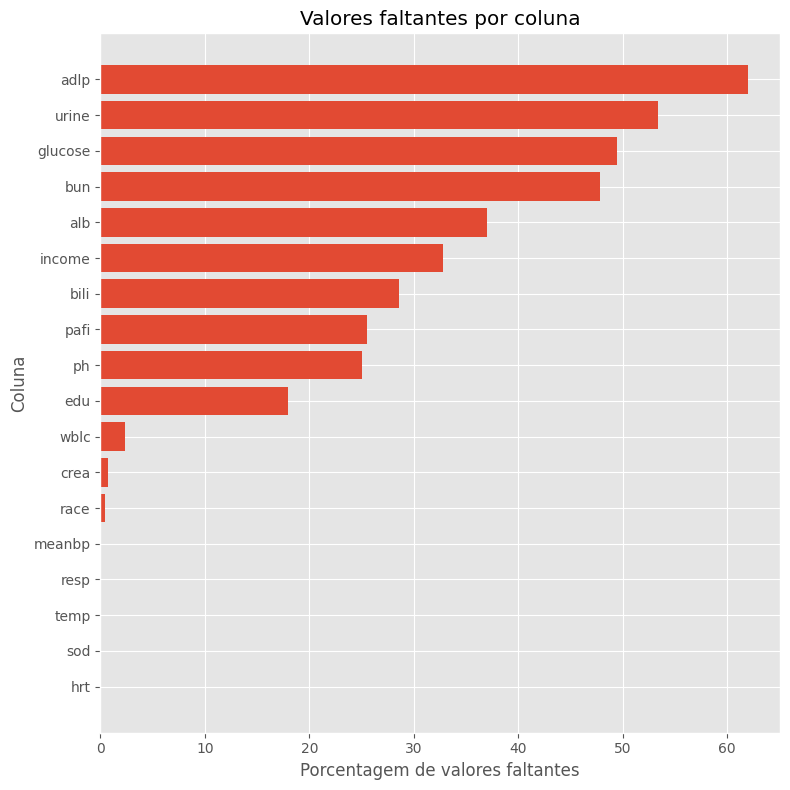

In [423]:
import matplotlib.pyplot as plt

# porcentagem de faltantes por coluna (só das que têm algum faltante)
colunas_uteis = list(atributo_util)
faltantes = X[colunas_uteis].isna().mean().sort_values(ascending=False) * 100
faltantes = faltantes[faltantes > 0]

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(faltantes.index, faltantes.values)
ax.invert_yaxis()   # a coluna com mais faltantes fica no topo
ax.set_xlabel("Porcentagem de valores faltantes")
ax.set_ylabel("Coluna")
ax.set_title("Valores faltantes por coluna")
plt.tight_layout()
plt.show()

Como podemos notar na tabela e no gráfico acima, existem atributos com muitos dados faltantes que podem prejudicar os nossos modelos.

Vamos dividir em 3 grupos diferentes:
1. atributos com menos de 25% dos dados faltantes --> como a maior parte desses dados está preenchida, então nos faltantes será colocado a mediana dos dados que temos
2. atributos com faltantes entre 25% e 50% --> nesse caso os faltantes já começam a ser mais relevante, porém na sua maioria são exames laboratoriais, e podem estar faltando porque o médico não pediu certos exames, uma vez que não seriam relevantes para aquele caso. Para os outros casos, temos dados faltantes com falta de informação mesmo. Logo, nessas informações faltantes será indicado que elas estão faltando com um valor específico, além de também serem preenchidos com a mediana.
3. atributos com mais de 50% dos dados faltantes --> serão descartados, pois as informações que temos nessas colunas são a minoria.

Assim, atualizando os nossos dicionários, temos:

In [424]:
atributo_util = {
    "age, sex, edu, income, race": "informaçoes conhecidas desde a entrada",
    "dzgroup": "diagnóstico do paciente conhecido na entrada dele",
    "dzclass": "versão mais ampla do dzgroup",
    "num.co, dementia, diabetes, ca": "doenças e comorbidades prévias do paciente",
    "hday": "dia de internação que o paciente entrou no estudo",
    "meanbp, hrt, resp, temp": "sinais vitais medidos no dia 3",
    "wblc, pafi, alb, bili, crea, sod, ph, glucose, bun": "exames e medidas do dia 3",
    "adlsc": "versão completa do adls"
}
atributo_descarte = {
    "scoma, sps, aps, surv2m, surv6m": "previsão de outro modelo",
    "charges, totcst, totmcst": "informação obtida depois do terceiro dia (custos totais da internação)",
    "avtisst": "informação obtida depois do terceiro dia",
    "prg2m, prg6m": "Estimativas de sobrevivência feitas pelos médicos com relação ao desfecho",
    "dnr, dnrday": "pode ser posterior ao dia 3 e tem alta relação com o desfecho",
    "urine, adlp" : "tem muitos dados faltantes",
    "adls": "indice de atividade diaria respondido por outra pessoa, muito correlacionado com adlsc"
}

def expandir(d):
    return {col.strip(): motivo
            for chaves, motivo in d.items()
            for col in chaves.split(",")}

atributo_util = expandir(atributo_util)
atributo_descarte = expandir(atributo_descarte)

todas = set(X.columns)
classificadas = set(atributo_util) | set(atributo_descarte)
print(todas - classificadas)   # esquecidas
print(classificadas - todas)  


set()
set()


Por fim, foi verificado a existencia de linhas duplicadas e foi visto que elas não existem nesse dataset, ou seja, todas as linhas são de pacientes diferentes, assim, podemos seguir para o próximo passo. 

### Análise do target 

Vamos analisar se o nosso target está desbalanceado plotando um gráfico dos alvos possíveis.

hospdead
0    6745
1    2360
Name: count, dtype: int64
hospdead
0    74.1
1    25.9
Name: proportion, dtype: float64


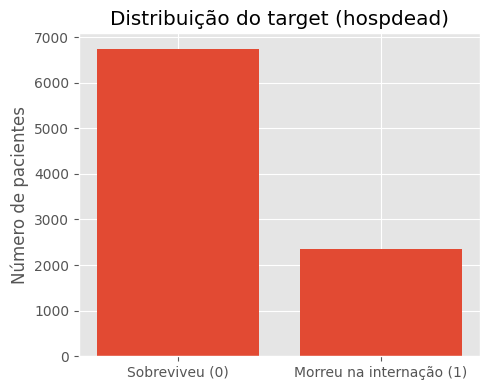

In [425]:
import matplotlib.pyplot as plt

contagem = y["hospdead"].value_counts()
proporcao = y["hospdead"].value_counts(normalize=True) * 100
print(contagem)
print(proporcao.round(1))

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["Sobreviveu (0)", "Morreu na internação (1)"], contagem.sort_index().values)
ax.set_ylabel("Número de pacientes")
ax.set_title("Distribuição do target (hospdead)")
plt.tight_layout()
plt.show()

Com essas informações, temos um desbalanceamento moderado, uma vez que aproximadamente 1/4 dos pacientes morreram na internação. Entretanto, sabemos que um modelo extremamentre simples que sempre prevê que um paciente sobreviveu acerta 74.1% das vezes (acuracia alta sem aprender nada). Por isso, esse será o piso de comparação (como será visto no modelo de baseline) e outras métricas também serão medidas. 

## Divisão em treino e teste 

Antes de tudo, vamos separar os dados em treino e teste, para não ocorrer vazamento de dados nesse projeto.

In [426]:
from sklearn.model_selection import train_test_split

X_util = X[list(atributo_util)]
y_alvo = y["hospdead"]

X_train, X_test, y_train, y_test = train_test_split(
    X_util, y_alvo,
    test_size=0.2,
    stratify=y_alvo,
    random_state=8,
)

print(X_train.shape, X_test.shape)
print(y_train.mean().round(3), y_test.mean().round(3))

(7284, 26) (1821, 26)
0.259 0.259


Os dados foram divididos na proporção de 80% para treino e 20% para teste apenas as colunas consideradas uteis para o projeto, definida pelos dicionários na etapa anterior. Além disso, os dados foram estratificados para manter a mesma proporção de morte (~26%) nos dados de treino e teste. Uma semente aleatória foi fixada para promover reprodutibilidade.

## Análise exploratória de dados 

Essa análise será feita apenas com base nos dados de treino. Primeiro, vamos usar o describe para observar um conjunto estatistico dos dados.

In [427]:
X_train.describe()


,age,edu,num.co,dementia,diabetes,hday,meanbp,hrt,resp,temp,wblc,pafi,alb,bili,crea,sod,ph,glucose,bun,adlsc
count,7284.000000,5977.000000,7284.000000,7284.000000,7284.000000,7284.000000,7283.000000,7283.000000,7283.000000,7283.000000,7121.000000,5398.000000,4598.000000,5215.000000,7231.000000,7283.000000,5435.000000,3681.000000,3797.000000,7284.000000
mean,62.654291,11.721432,1.880011,0.031713,0.198243,4.328803,84.400110,97.128972,23.380887,37.097398,12.368345,240.235698,2.949777,2.545680,1.780262,137.552520,7.415483,159.460907,32.387332,1.882515
std,15.625096,3.448589,1.350400,0.175248,0.398703,8.895363,27.548514,31.522144,9.607009,1.253917,9.474916,109.118910,0.892550,5.297516,1.714496,6.050219,0.080633,88.415083,26.465730,2.003054
min,18.041990,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,32.000000,0.000000,12.000000,0.399963,0.099991,0.099991,110.000000,6.829102,0.000000,1.000000,0.000000
25%,52.805235,10.000000,1.000000,0.000000,0.000000,1.000000,63.000000,72.000000,18.000000,36.093750,6.899414,157.031250,2.399902,0.500000,0.899902,134.000000,7.379883,102.000000,14.000000,0.000000
50%,64.882965,12.000000,2.000000,0.000000,0.000000,1.000000,77.000000,100.000000,24.000000,36.695310,10.500000,224.437500,2.899902,0.899902,1.199951,137.000000,7.419922,134.000000,24.000000,1.000000
75%,73.986240,14.000000,3.000000,0.000000,0.000000,3.000000,107.000000,120.000000,28.000000,38.093750,15.298828,306.625000,3.599609,1.899902,1.899902,141.000000,7.469727,188.000000,42.000000,3.000000
max,100.849000,31.000000,9.000000,1.000000,1.000000,147.000000,195.000000,300.000000,90.000000,41.695310,200.000000,890.375000,29.000000,54.796875,21.500000,181.000000,7.769531,1092.000000,192.000000,7.073242


Com isso, podemos extrair algumas informações, como por exemplo a idade média dos pacientes fica em torno de 62 anos. Na maioria dos atributos, a média e a mediana (50%) estão próximas, o que indica que nessas colunas não temos valores muito longe dos outros, e assim, apresenta simetria. Mas isso é um palpite, então agora vamos observar a distribuição de alguns atributos.

Na próxima célula vamos observar a distribuição numérica de alguns atributos com poucas categorias e ver a relação de cada um deles com a taxa de morte na internação.

In [428]:
treino = X_train.copy()
treino["hospdead"] = y_train

for col in ["sex", "race", "income", "ca", "dzgroup", "dementia", "diabetes"]:
    resumo = treino.groupby(col, dropna=False)["hospdead"].agg(["count", "mean"])
    # agg calcula para cada grupo a qtd de pacientes e a média
    resumo.columns = ["pacientes", "taxa_morte"]
    print(col)
    print(resumo.round(3))
    print()

sex
        pacientes  taxa_morte
sex                          
female       3196       0.261
male         4088       0.258

race
          pacientes  taxa_morte
race                           
asian            64       0.391
black          1142       0.276
hispanic        227       0.247
other            95       0.295
white          5719       0.253
NaN              37       0.405

income
            pacientes  taxa_morte
income                           
$11-$25k         1208       0.237
$25-$50k          833       0.236
>$50k             558       0.226
under $11k       2309       0.250
NaN              2376       0.295

ca
            pacientes  taxa_morte
ca                               
metastatic       1492       0.172
no               4774       0.261
yes              1018       0.377

dzgroup
                   pacientes  taxa_morte
dzgroup                                 
ARF/MOSF w/Sepsis       2816       0.340
CHF                     1107       0.064
COPD                 

Como podemos observar, em alguns atributos a taxa de morte não varia significamente entre as categorias, como no caso de "sex", em que a distribuição entre homens e mulheres é parecida. Todavia, temos outros atributos com diferenças mais significantes, como o atributo "dzgroup", em que a taxa de morte varia muito entre cancer de colo (5,5%) e coma (60%) por exemplo, mostrando assim, que este atributo é importante para a previsão do target nos modelos.

Diante disso, vamos analisar a distribuição dos valores de alguns atributos em histogramas.

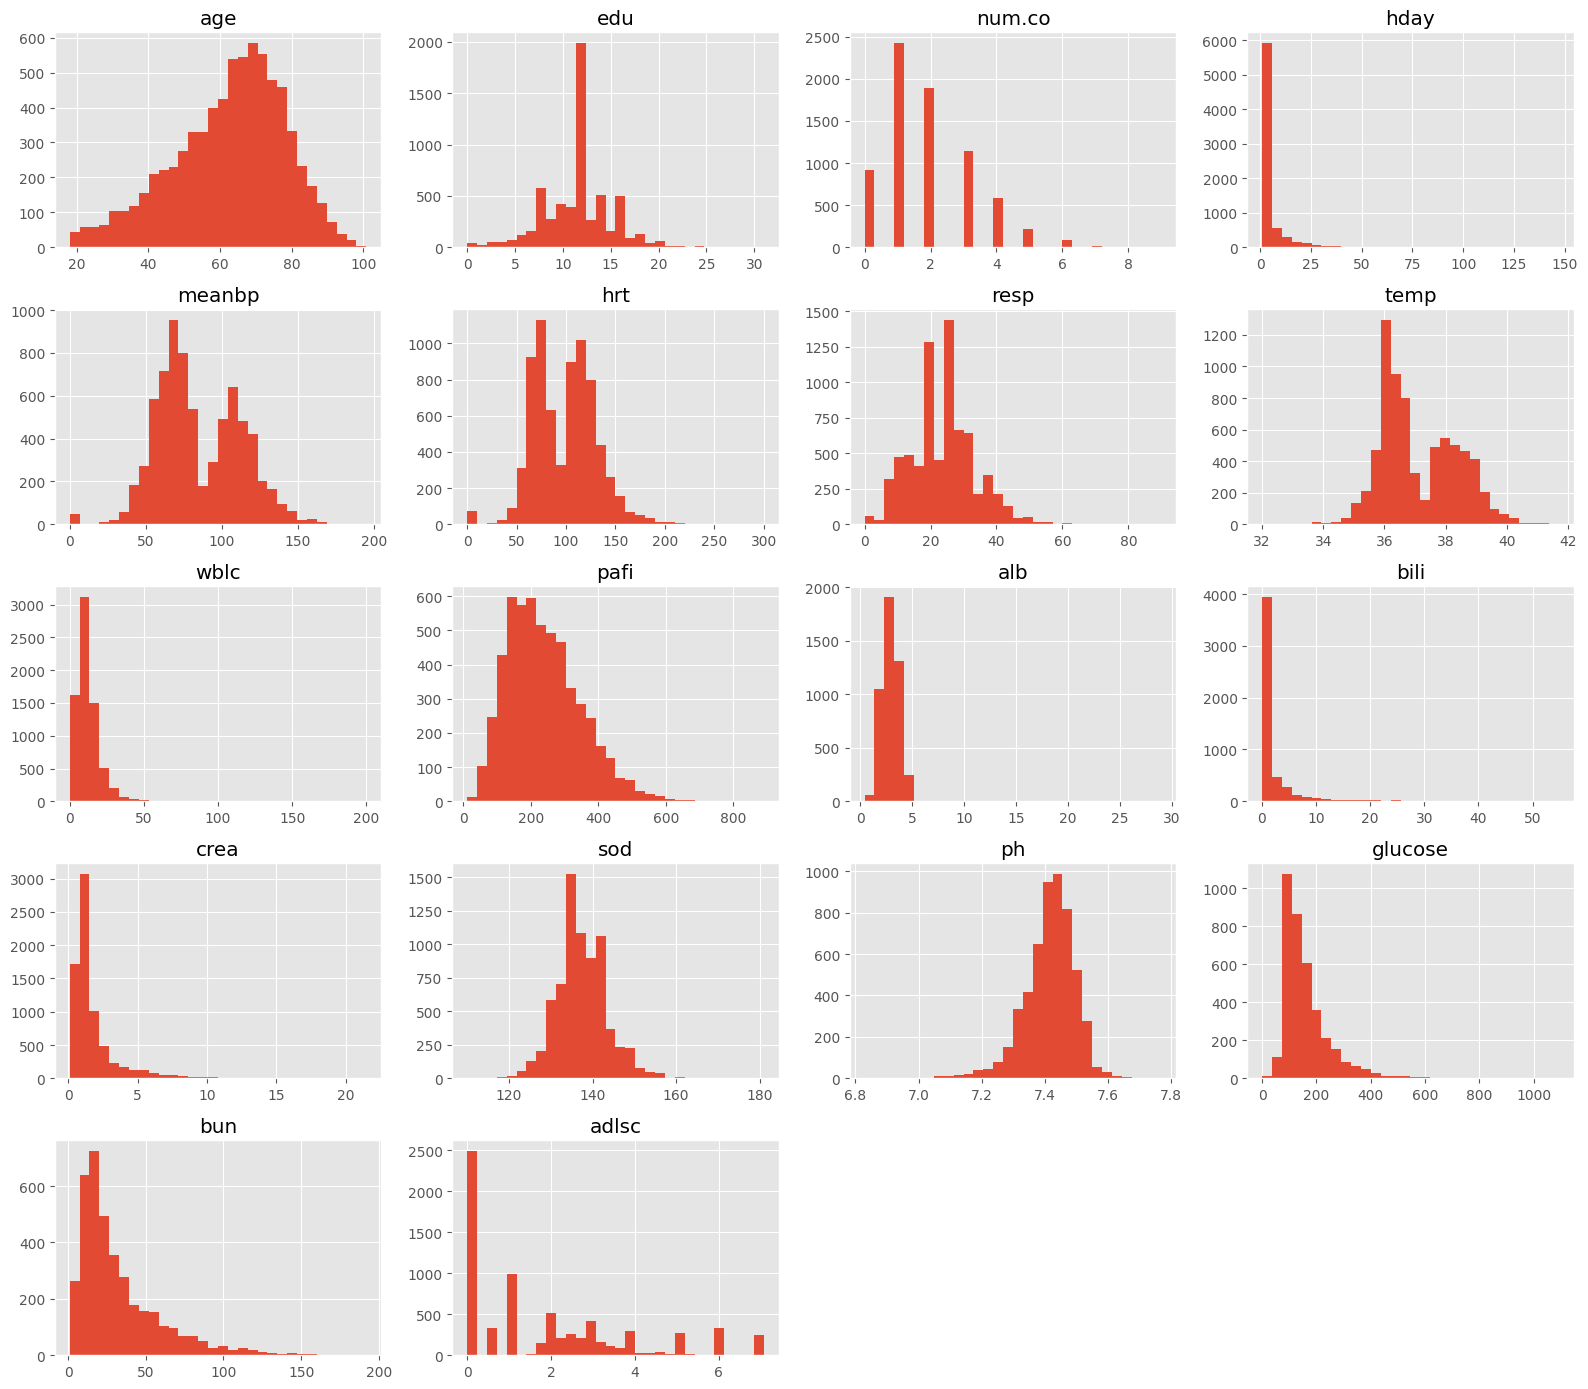

In [429]:
numericas = ["age", "edu", "num.co", "hday", "meanbp", "hrt", "resp", "temp",
             "wblc", "pafi", "alb", "bili", "crea", "sod", "ph", "glucose", "bun", "adlsc"]

X_train[numericas].hist(bins=30, figsize=(16, 14))
plt.tight_layout()
plt.show()

Podemos observar que a maioria dos gráficos possui uma distribuição variada dos valores, porém, temos alguns dados estranhos, como pacientes com a respiração ("resp"), batimento cardiaco ("hrt") e a pressão arterial média ("meanbp") zerados, o que seria impossível para um indivíduo vivo. Contudo, essa proporção é muito pequena em relação ao resto dos dados (menos de 1%). Logo, irei manter pois afetam menos de 1% das linhas e os modelos de árvores são pouco sensíveis a isso. Se isso afetar modelos como o K-NN, irei corrigir isso.

Agora nesta etapa, vamos comparar essa distribuição dos atributos visto anteriormente com a distribuição do target, para observar se os pacientes mortos possuem valores diferentes em comparação aos pacientes vivos para cada atributo analisado no último histograma. Os atributos que mostram diferenças claras no deslocamento das curvas serão mais informativos. 

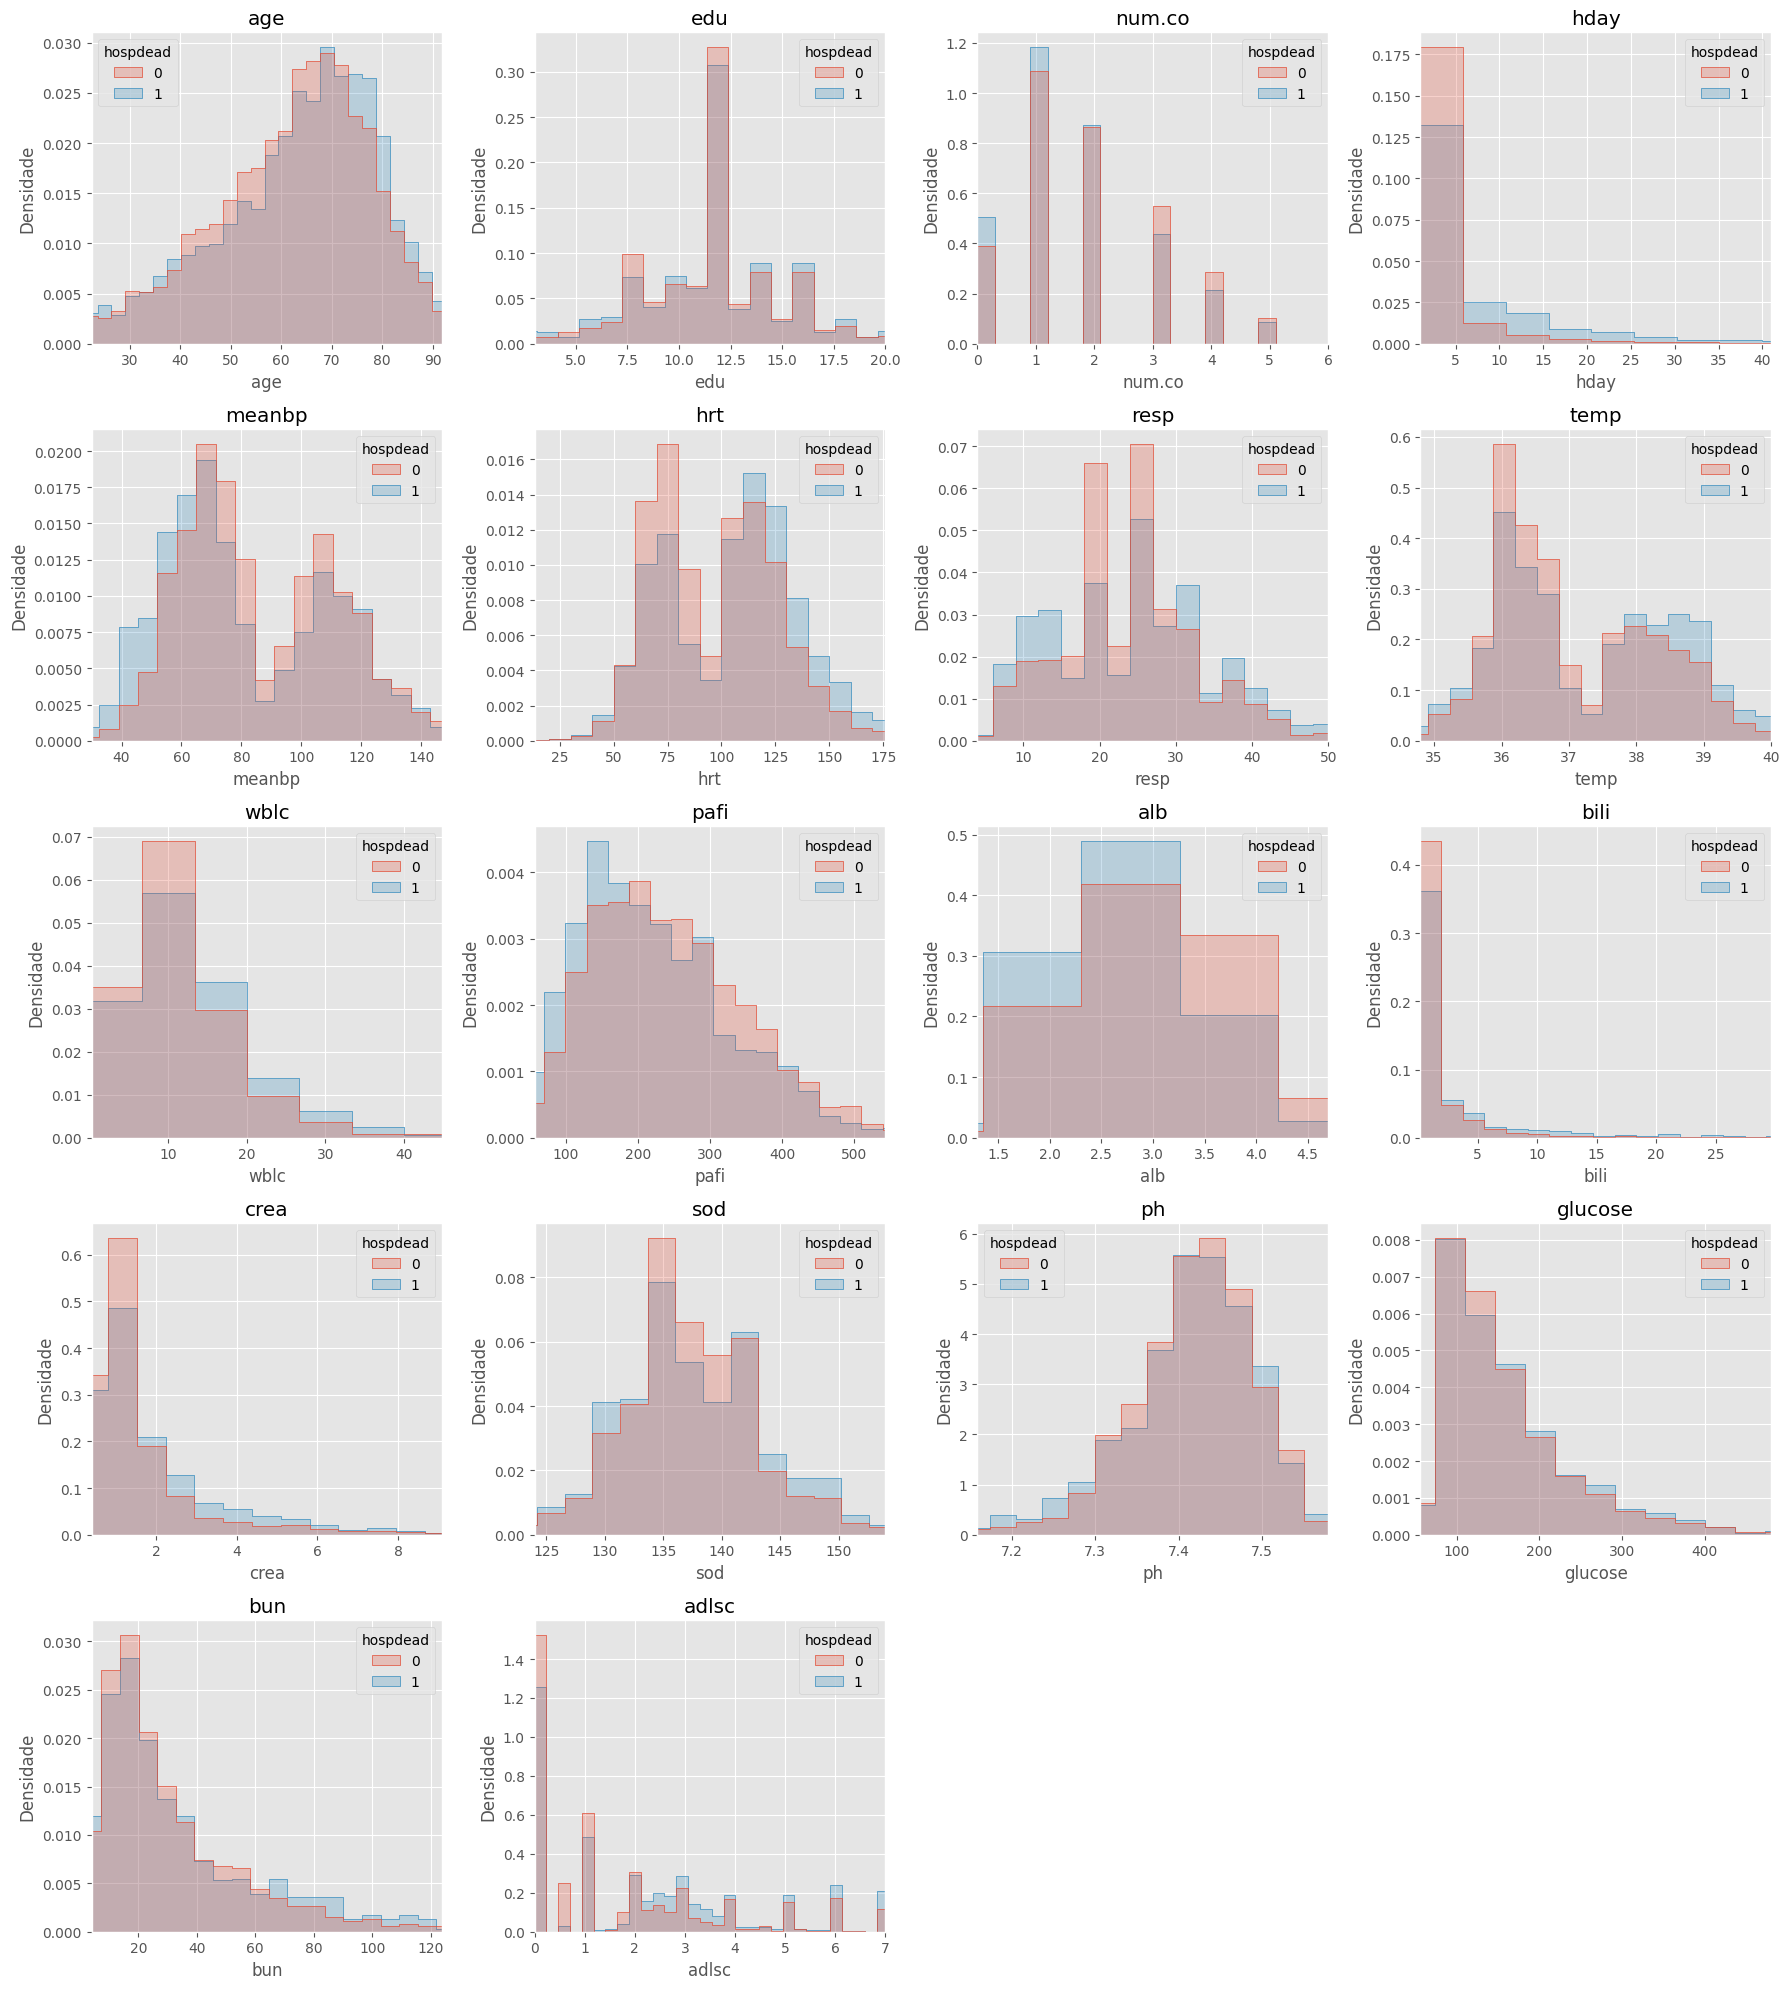

In [430]:
import seaborn as sns
import matplotlib.pyplot as plt

treino = X_train.copy()
treino["hospdead"] = y_train

fig, axes = plt.subplots(5, 4, figsize=(18, 20))
axes = axes.flatten()

for ax, col in zip(axes, numericas):
    sns.histplot(data=treino, x=col, hue="hospdead", bins=30,
                 stat="density", common_norm=False, element="step", ax=ax)
    # só para visualização: corta as caudas extremas (1% de cada lado)
    ax.set_xlim(treino[col].quantile(0.01), treino[col].quantile(0.99))
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Densidade")

for ax in axes[len(numericas):]:
    ax.axis("off")
# isso faz pra não ter gráfico vazio, pra aparecer só branco no final
plt.tight_layout()
plt.show()

Como pode ser visto, atributos como "alb", "hrt" e "bili" possuem diferenças claras na sua distribuição, enquanto em "resp" e "sod" temos mortos mais nos extremos dos dois lados. Por fim, atributos como "edu" e "bun" apresentaram pouca diferença.

Com isso, vamos fazer um mapa da Correlação de Spearman para analisar se as variáveis (atributos) são parecidas entre si, ou se cada coluna traz uma informação diferente. Se a correlação de dois atributos for muito alta, é valido assumir que existe uma redundância ali.

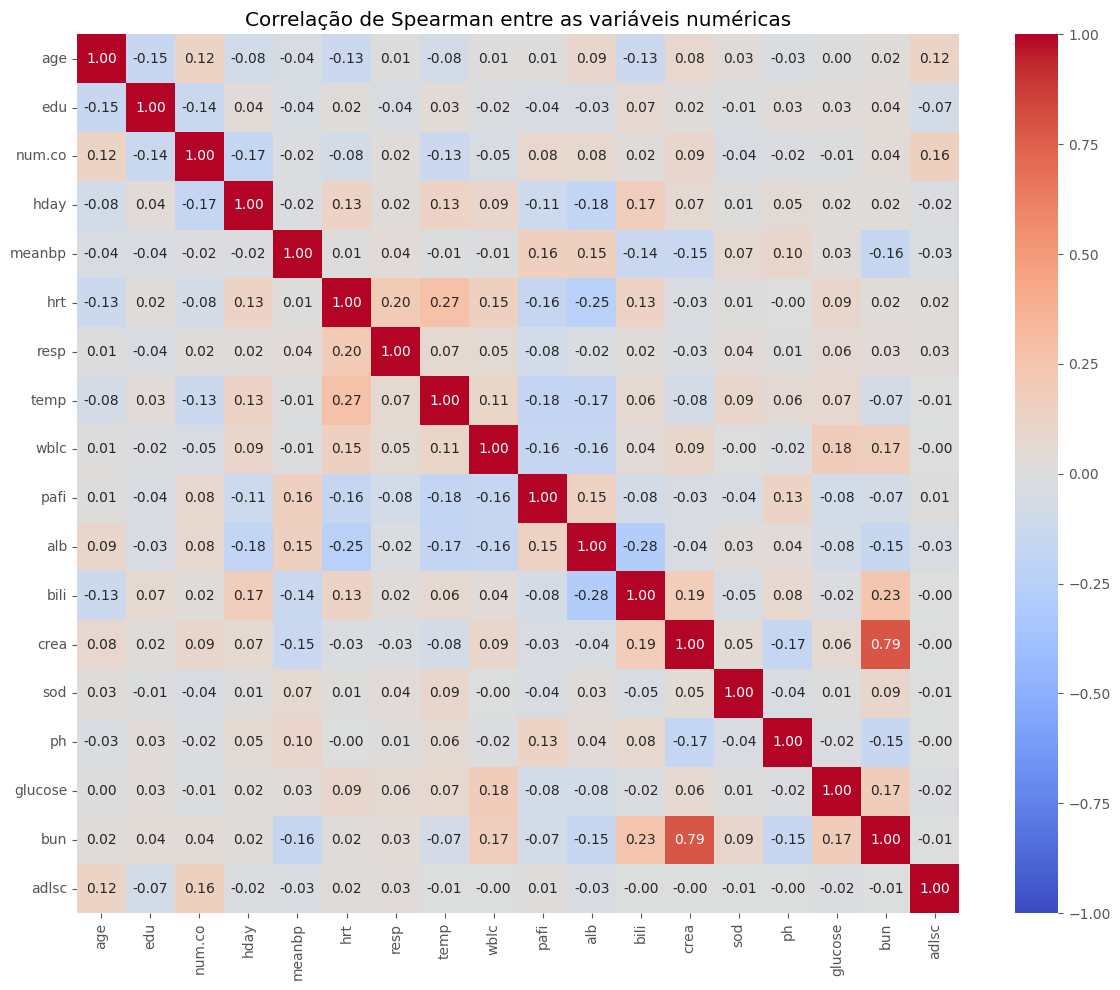

In [431]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = treino[numericas].corr(method="spearman")

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            vmin=-1, vmax=1, ax=ax)
            # annot = true mostra o valor dentro das celulas de cores
ax.set_title("Correlação de Spearman entre as variáveis numéricas")
plt.tight_layout()
plt.show()

Assim, é notório que os únicos atributos com valor de correlação mais alto é a variável "bun" e "crea", o que faz sentido, já que esses dois exames estão ligados à funções dos rins. 

Com isso, vamos para o pré-processamento dos dados.

## Pré-processamento 

Primeiro, vamos dividir as colunas em 3 tipos, pois cada dado exige um tratamento diferente para os modelos. Foi dividido em grupo de números (como idade), grupo de valores binários(como sexo) e categorias em texto (como renda). Por fim, foi verificado se alguma coluna não foi colocada na divisão em grupos.

In [432]:
cols_num = ["age", "edu", "num.co", "hday", "meanbp", "hrt", "resp", "temp",
            "wblc", "pafi", "alb", "bili", "crea", "sod", "ph", "glucose",
            "bun", "adlsc"]
cols_bin = ["sex", "dementia", "diabetes"]
cols_cat = ["race", "dzgroup", "dzclass", "ca", "income"]

todas_cols = cols_num + cols_bin + cols_cat
print(len(todas_cols), set(todas_cols) == set(X_train.columns))   


26 True


Olhando primeiro para as númericas, podemos observar que possuem diversos valores faltantes. Assim, vamos preencher os faltantes com a mediana dos valores dos atributos com 25% a 50% de dados faltantes. Além disso, vamos criar uma coluna extra que indica que o valor esta faltando, para colunas com muitos faltantes, uma vez que certos valores podem estar faltando por motivos externos, como exames que os médicos não pediram para certos casos. 

In [433]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
import numpy as np

cols_num_ind = ["glucose", "bun", "alb", "bili", "pafi", "ph"]
cols_num_simples = [c for c in cols_num if c not in cols_num_ind]

prep_num = ColumnTransformer([
    ("num_ind", SimpleImputer(strategy="median", add_indicator=True), cols_num_ind),
    ("num_simples", SimpleImputer(strategy="median"), cols_num_simples),
])
# o simpleimputer substitui os NaN pela mediana dos valores e o add_indicator coloca uma coluna indicando 
# colunas com muitos faltantes 

Xt = prep_num.fit_transform(X_train)
# fit calcula a mediana e transform aplica o preenchimento 
print(Xt.shape)

(7284, 24)


Como podemos ver, agora temos 24 colunas desse grupo, ou seja, 18 colunas originais e 6 novas colunas indicadoras de muitos valores faltantes.

Assim, vamos analisar o grupo dos valores categóricos. Vamos transformar cada uma dessas opções em colunas de 0 e 1 com o OneHotEncoder, para os modelos conseguirem entender esses atributos.

In [434]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# pipeline é a receita --> passo a passo a ser seguido
prep_cat = Pipeline([
    # strategy diz pra preencher com valor constante
    ("Passo A", SimpleImputer(strategy="constant", fill_value="desconhecido")),
    ("Passo B", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    # handle_unknown lida com erros de categorias desconhecidas e só tranforma eles em zero, e o 
    # sparse_output faz o resultado vir em uma tabela comum
])

Xc = prep_cat.fit_transform(X_train[cols_cat])
#fit_tranform aplica a receita 
print(Xc.shape)

(7284, 26)


Este código troca os faltantes pelo valor "desconhecido" (quem faz isso é o SimpleImputer) e cria colunas de 0/1 para cada categoria (quem faz isso é o OneHotEncoder). Na saída, podemos ver os 7284 pacientes e as 26 colunas de 0/1.

Dessa maneira, vamos aplicar a mesma ideia para valores binários, tranformando em apenas uma coluna que representa o 0 ou o 1. 

In [435]:
prep_bin = OneHotEncoder(drop="if_binary", sparse_output=False)

Xb = prep_bin.fit_transform(X_train[cols_bin])
print(Xb.shape)
print(prep_bin.get_feature_names_out(cols_bin))

(7284, 3)
['sex_male' 'dementia_1' 'diabetes_1']


Com tudo isso feito, vamos juntar tudo com o ColumnTransformer, que aplica cada tratamento ao seu grupo de colunas e retorna o resultado. Somando todas as colunas obtidas, agora temos 53 colunas, sem nenhum valor faltante.

In [436]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
import numpy as np

cols_num_ind = ["glucose", "bun", "alb", "bili", "pafi", "ph"]
cols_num_simples = [c for c in cols_num if c not in cols_num_ind]

preprocessador = ColumnTransformer([
    ("num_ind", SimpleImputer(strategy="median", add_indicator=True), cols_num_ind),
    ("num_simples", SimpleImputer(strategy="median"), cols_num_simples),
    ("bin", OneHotEncoder(drop="if_binary", sparse_output=False), cols_bin),
    ("cat", Pipeline([
        ("imp", SimpleImputer(strategy="constant", fill_value="desconhecido")),
        ("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ]), cols_cat),
])

Xt = preprocessador.fit_transform(X_train)
print(Xt.shape)
print(np.isnan(Xt).sum())

(7284, 53)
0


## Modelos 

### Validação cruzada

Antes de tudo, vamos fazer a validação cruzada. Aqui, vamos dividir o treino em 5 partes (os folds), e repetir a avaliação 5 vezes, para que o modelo avalie em pacientes que ele não tenha visto previamente. Ela foi estratificada para manter a proporção de 26% de mortes em todos os folds, e usa apenas o treino para não ocorrer vazamento de dados. O mesmo cv será usado em todos os modelos.

In [437]:
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=8)

metricas = {
    "accuracy": "accuracy",
    "precisao": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
    "pr_auc": "average_precision",
    "roc_auc": "roc_auc",
}
         # treino     # teste (parte escondida) 
for i, (idx_treino, idx_val) in enumerate(cv.split(X_train, y_train), start=1):
    print(f"Rodada {i}: treino={len(idx_treino)}, validação={len(idx_val)}, "
          f"proporção de mortes na validação={y_train.iloc[idx_val].mean():.3f}")

SEMENTE_ALEATORIA = 8

Rodada 1: treino=5827, validação=1457, proporção de mortes na validação=0.259
Rodada 2: treino=5827, validação=1457, proporção de mortes na validação=0.259
Rodada 3: treino=5827, validação=1457, proporção de mortes na validação=0.259
Rodada 4: treino=5827, validação=1457, proporção de mortes na validação=0.259
Rodada 5: treino=5828, validação=1456, proporção de mortes na validação=0.259


Com essa divisão feita, vamos fazer um breve resumo de cada parte antes de continuar:

Limiar: é o ponto de corte que transforma uma probabilidade numa resposta de “sim” ou “não”. Ou seja, esse número decide a partir de quantos % que ele deixa de prever "sobrevive" e passa a prever "morte". Um limiar baixo pode resultar em mais alarmes falsos, e assim, um limiar alto pode deixar passar mais mortes. 

Agora, para as métricas:

1.  acurácia: é o valor que diz que, de todas as previsões feitas, quantas estavam corretas
2.  precisão: dentre tudo que o modelo marcou como morte na internação, essa é a fração de quem realmente morreu. Nesta métrica é identificado os alarmes falsos, já que quanto maior o número de alarmes falsos, menor a precisão. 
3.  recall: dentre todas as mortes na internação que existem, a fração que o modelo encontrou. Nesse caso, o recall mostra quantos pacientes que morreram o modelo conseguiu apontar, e o que falta para 100% são mortes não detectadas.
4.  f1: é a média harmônica entre a precisão e o recall, ela é puxada para o menor dos dois valores, por isso, se a precisão ou o recall for perto de zero, o F1 também fica perto de zero
5.  pr_auc: A curva precisão-recall mostra, para cada limiar, a precisão (eixo vertical) contra o recall (eixo horizontal). A área sob ela resume o desempenho só da morte na internação, sem depender de um limiar.

6.  roc_auc: A curva roc mostra, para cada limiar, o recall contra a taxa de falsos positivos. A roc_auc é a área sob essa curva, e equivale à probabilidade de o modelo dar uma probabilidade de morte maior a um paciente que morreu do que a um que sobreviveu.

**Observação:** as métricas 1 ate 4 dependem do limiar, enquanto as métricas 5 e 6 não dependem.

**Observação2:** Na área da saúde, é mais grave deixar passar possíveis mortes do que termos alarmes falsos, e por conta disso, a métrica recall é mais relevante do que a métrica precisão. Mas também, o recall sozinho pode ser enganado, e por isso, vamos usar como a métrica principal o pr_auc, que não depende do limiar.

### Baseline 

O primeiro modelo a ser feito será o baseline, um modelo que não aprende nada com os atributos e só chuta de acordo com a proporção de mortes do treino, ou seja, nesse caso sempre chuta que o paciente continua vivo. Todos os modelos feitos após ele devem ser melhor que ele, senão também não aprenderam nada.

In [438]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

baseline = Pipeline([
    ("prep", preprocessador),
    ("modelo", DummyClassifier(strategy="prior")),
])

res = cross_validate(baseline, X_train, y_train, cv=cv, scoring=metricas)

for nome in metricas:
    print(f"{nome}: {res['test_' + nome].mean():.3f}")

accuracy: 0.741
precisao: 0.000
recall: 0.000
f1: 0.000
pr_auc: 0.259
roc_auc: 0.500


Em relação ao baseline, podemos observar que a acurácia de 74,1 % pode ser enganosa, uma vez que parece um número alto, mas como visto antes na análise do alvo, é apenas a proporção de sobreviventes no conjunto de dados, e assim, ao chutar a classe numerosa, o modelo acerta grande quantidade dos pacientes sem detectar nada. 

Além disso, como o baseline nunca diz que alguem vai morrer, então ele nunca acerta uma morte e também nunca deu um alarme falso falando que alguem iria morrer enquando essa pessoa sobrevive. Por causa disso, as métricas precisão e recall são nulas nesse modelo, e por consequência, f1 também é igual a zero. 

Por fim, para as medidas pr_auc e roc_auc, vemos que neste modelo todos os pacientes recebem a mesma probabilidade, e por isso, não consegue distinguir quem tem mais risco. Com isso, roc_auc possui uma ordenação ao acaso, e por isso é 50% e pr_auc possui o valor de referência proporcional às mortes do conjunto de dados.

Como o baseline não possui hiperparâmetros, não vamos utilizar o optuna ainda.

### Regressão logística 

Após realizar o baseline, vamos fazer o primeiro modelo que aprende de verdade, a regressão logística. Esta é uma técnica estatística e de aprendizado de máquina usada para prever a probabilidade de ocorrência de um resultado categórico, ideal para o nosso dataset com target binário. Nesta primeira parte do modelo, vamos usar os seguintes hiperparâmetros:
- C: controla a regularização do modelo, ou seja valores menores aumentam a regularização e simplificam o modelo, e valores maiores fazem o contrário.
- penalty: define o tipo de regularização aplicada aos pesos para evitar overfitting (l1, l2, none, etc.)
- class_weight: ajusta o peso das classes, muito útil neste caso com desbalanceamento entre os targets. 
- solver: é o algoritmo de otimização que define como o modelo encontra os melhores coeficientes ('lbfgs' é o padrão e 'liblinear' é bom para l1/l2). 

Com isso, será feito um pipeline com os dados da validação cruzada, e as métricas serão estudadas de um modelo padrão da regressão logística. Os valores padrão que o modelo usa são: C=1, l2, sem pesos, lbfgs.

In [439]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logreg = Pipeline([
    ("prep", preprocessador),
    ("escala", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=1000)),
])

res_lr = cross_validate(logreg, X_train, y_train, cv=cv, scoring=metricas)

for nome in metricas:
    notas = res_lr['test_' + nome]
    print(f"{nome}: {notas.mean():.3f}")

accuracy: 0.778
precisao: 0.628
recall: 0.354
f1: 0.453
pr_auc: 0.558
roc_auc: 0.789


Como podemos observar, as métricas já tiveram uma melhora. A métrica pr_auc teve um valor maior que o dobro do piso visto no baseline, ou seja, já é melhor que o acaso. Além disso, o modelo dá probabilidade maior de morte a quem morreu, em cerca de 79% dos pares sorteados (um que morreu e um que sobreviveu). A acurácia também subiu um pouco, a precisão do modelo foi de 63 % e por meio do recall podemos ver que o modelo pega 35% das mortes, sendo esse o ponto fraco vindo do limiar de 0,5. Como só aproximadamente 26% morrem, poucos pacientes passam de 50% de probabilidade. Dá para ver que as duas AUC, que não dependem do limiar, estão boas, então o modelo ordena bem o risco. 

Com isso, vamos ajustar esse modelo com novos hiperparâmetros escolhidos pelo optuna.

Vamos fazer a busca para encontrar hiperparâmetros melhores, e para isso precisamos definir o espaço de busca de cada um. 
- C: Valores pequenos significam regularização forte e grandes significam regularização fraca. Neste modelo, foi escolhido o intervalo de 1e-4 a 1e2 para cobrir desde um modelo muito restrito até um quase sem regularização, e usamos escala logarítmica porque o efeito do C muda por ordens de grandeza: a diferença entre 0,001 e 0,01 altera bastante o modelo, enquanto a diferença entre 50 e 51 é insignificante.
- Penalty: decide entre os dois tipos de regularização, o L1 e o L2
- Class_weight: pode ser None ou "balanced", sabendo que o "balanced" da mais peso aos erros na classe da morte na internação para compensar o desbalanceamento. Como o pr_auc depende apenas da ordenação das probabilidades, esperamos que esse hiperparâmetro tenha pouco efeito na métrica.
- Escala: ajusta os números de cada coluna antes de o modelo vê-los. Não é um hiperparâmetro da regressão logística em si, mas uma escolha do pipeline que o Optuna também testa. Ele escolhe entre StandardScaler (para cada coluna, subtrai a média e divide pelo desvio-padrão, e assim todas as colunas passam a ter média 0 e desvio 1, resolvendo a diferença de unidade) e PowerTransformer (aplica uma transformação matemática que deixa a distribuição mais simétrica, parecida com uma normal, e depois também padroniza para média 0 e desvio 1. Ele faz tudo o que o StandardScaler faz, e ainda corrige a assimetria.)

In [440]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.pipeline import Pipeline

def cria_instancia_modelo_regls(trial):
    escala = trial.suggest_categorical("escala", ["standard", "power"])
    escalador = StandardScaler() if escala == "standard" else PowerTransformer()

    hparam_regls = {
        # espaço de busca
        "C": trial.suggest_float("C", 1e-4, 1e2, log=True),
        "penalty": trial.suggest_categorical("penalty", ["l1", "l2"]),
        "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
        # argumentos fixos
        "solver": "liblinear",
        "max_iter": 1000,
        "random_state": SEMENTE_ALEATORIA,
    }

    return Pipeline([
        ("prep", preprocessador),
        ("escala", escalador),
        ("modelo", LogisticRegression(**hparam_regls)),
    ])

Nesta primeira célula do Optuna, vemos que a função cria_instancia_modelo recebe os intervalos de busca dos hiperparâmetros e devolve um pipeline com pré-processamento, escalonamento e a própria regressão logística. O padrão do scikit-learn (lbfgs) não aceita l1, por isso o solver foi trocado para liblinear, que aceita tanto l1 quanto l2.

Com isso, vamos criar a função objetivo, que é a função que irá computar a métrica de interesse, que nesse caso é o pr_auc.

In [441]:
from sklearn.model_selection import cross_val_score
def funcao_objetivo_regls(trial, X, y, cv):
  modelo = cria_instancia_modelo_regls(trial)
  notas = cross_val_score(modelo, X, y, scoring="average_precision", cv=cv, n_jobs=-1)
  return notas.mean()

Após isso, vamos criar um estudo e usar a função objetivo com apenas um argumento, o trial

In [442]:
import optuna
from optuna import create_study
from optuna.samplers import TPESampler

optuna.logging.set_verbosity(optuna.logging.WARNING)

NOME_DO_ESTUDO_regls = "regressao_logistica_pr-auc"

estudo_regls = create_study(
    direction="maximize",
    sampler=TPESampler(seed=SEMENTE_ALEATORIA),
    study_name=NOME_DO_ESTUDO_regls,
    storage=f"sqlite:///{NOME_DO_ESTUDO_regls}.db",
    load_if_exists=True,
)

def funcao_objetivo_parcial_regls(trial):
    return funcao_objetivo_regls(trial, X_train, y_train, cv)

Por fim, vamos rodar a busca de verdade, com 100 trials, e depois mostra o melhor resultado para ser usado mais a frente 

In [443]:
NUM_TENTATIVAS = 100

# conta só os trials concluídos, para não acumular trials se a célula for rodada de novo
feitos = len([t for t in estudo_regls.trials if t.state.name == "COMPLETE"])
estudo_regls.optimize(funcao_objetivo_parcial_regls, n_trials=max(0, NUM_TENTATIVAS - feitos))

melhor_trial_regls = estudo_regls.best_trial

print(f"Número do melhor trial: {melhor_trial_regls.number}")
print(f"Parâmetros do melhor trial: {melhor_trial_regls.params}")
print(f"O melhor valor para pr_auc foi: {estudo_regls.best_value}")

Número do melhor trial: 25
Parâmetros do melhor trial: {'escala': 'power', 'C': 0.20266588041178285, 'penalty': 'l1', 'class_weight': None}
O melhor valor para pr_auc foi: 0.5655491227127165


Com isso, podemos observar que obtemos C ~ 0.2026, penalty = l1, sem peso para as classes e com escala = power. Além disso, o nosso novo valor de pr_auc foi de aproximadamente 0.5655.

Assim, vamos observar os hiperparâmetros mais importantes para o modelo com um gráfico. Além disso, para observar o resultado de cada trial, vamos plotar outro gráfico da busca feita pelo Optuna.

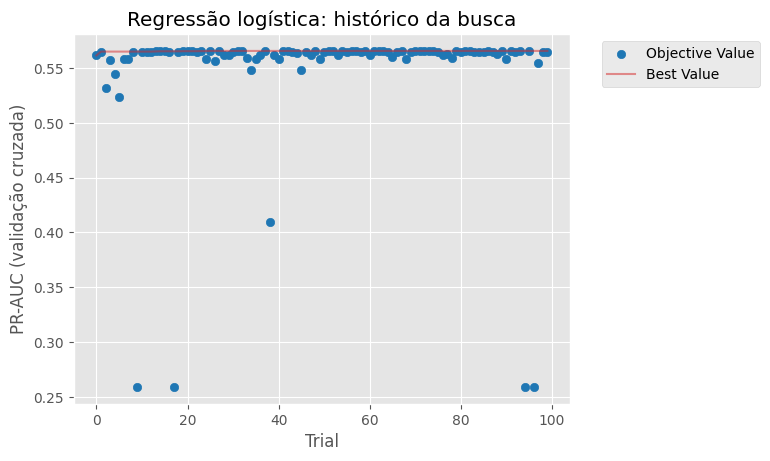

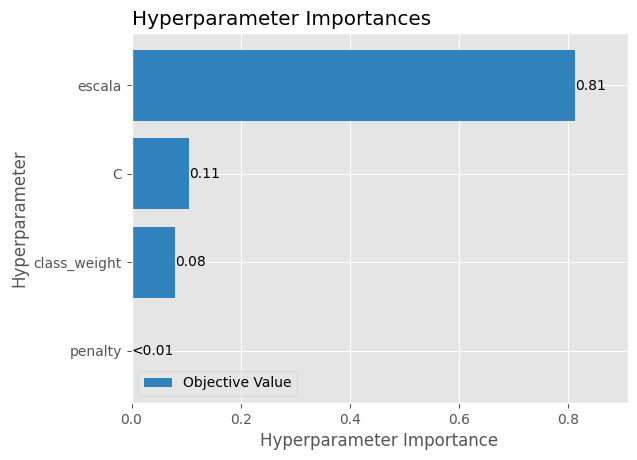

In [444]:
import warnings
import matplotlib.pyplot as plt
from optuna.exceptions import ExperimentalWarning
from optuna.visualization.matplotlib import plot_param_importances, plot_optimization_history

warnings.filterwarnings("ignore", category=ExperimentalWarning)

ax = plot_optimization_history(estudo_regls)
ax.set_ylabel("PR-AUC (validação cruzada)")
ax.set_title("Regressão logística: histórico da busca")
plt.show()

plot_param_importances(estudo_regls)
plt.show()

Podemos observar que a escala é mais importante para o modelo. Uma possível explicação para isso seria que o PowerTransformer muda a forma das variáveis assimétricas, enquanto o C varia muito sem mudar a nota. 

Os trials do histórico de busca tiveram resultados parecidos para o pr_auc. Como o melhor trial foi o 25 e a linha de melhor valor parou de subir a partir disso, então podemos concluir que a busca convergiu e 100 trials foram suficientes. 

Finalmente, vamos criar um modelo com os melhores hiperparâmetros encontrados pelo Optuna e checar seu desempenho.

In [445]:
logreg_otimizada = cria_instancia_modelo_regls(melhor_trial_regls)

res_lr_otimizada = cross_validate(logreg_otimizada, X_train, y_train, cv=cv, scoring=metricas)

for nome in metricas:
    print(f"{nome}: {res_lr_otimizada['test_' + nome].mean():.3f}")
    

accuracy: 0.779
precisao: 0.627
recall: 0.368
f1: 0.463
pr_auc: 0.566
roc_auc: 0.790



A melhora dos valores padrões para o Optuna foi bem baixa, de 0.558 para 0.566 no pr_auc. Por isso, não da pra afirmar que a otimização melhorou de verdade. Contudo, como a regressão logística é um modelo simples, com pouco o que ajustar, o resultado é que o padrão já estava perto do melhor.

### Algoritmo K-NN

Com isso, vamos seguir para o próximo modelo usando o algoritmo K-NN. Este algoritmo é um classificador de aprendizado supervisionado, que usa a proximidade para fazer classificações ou previsões sobre o agrupamento de um determinado ponto de dados. Vamos fazer um pipeline com pre-processador, escala e o modelo

In [446]:
from sklearn.neighbors import KNeighborsClassifier

knn = Pipeline([
    ("prep", preprocessador),
    ("escala", StandardScaler()),
    ("modelo", KNeighborsClassifier()),
])

res_knn = cross_validate(knn, X_train, y_train, cv=cv, scoring=metricas)

for nome in metricas:
    print(f"{nome}: {res_knn['test_' + nome].mean():.3f}")

accuracy: 0.749
precisao: 0.526
recall: 0.329
f1: 0.405
pr_auc: 0.436
roc_auc: 0.714


Podemos olhar que os resultados do K-NN padrão foram melhores do que os do baseline, então aprendeu algo, mas foram bem piores do que o da regressão logística em todas as métricas. Uma possível causa é que, com os valores padrões de k = 5 e pesos uniformes, a probabilidade de morte só pode assumir seis valores (0, 0.2, 0.4, 0.6, 0.8 e 1), então muitos pacientes empatam e a ordenação do risco fica superficial, o que prejudica o pr_auc. Outra possível causa é que a distância é calculada sobre dezenas de colunas, muitas delas binárias, e atributos pouco informativos diluem a distância entre os vizinhos. 

Com isso, vamos utilizar redução de dimensionalidade para reduzir as colunas, e para isso, iremos plotar um gráfico para descobrir quantas componentes é preciso manter para não perder muita informação. 

Atributos após o pré-processamento: 53
Componentes necessárias para 90% da variância: 34


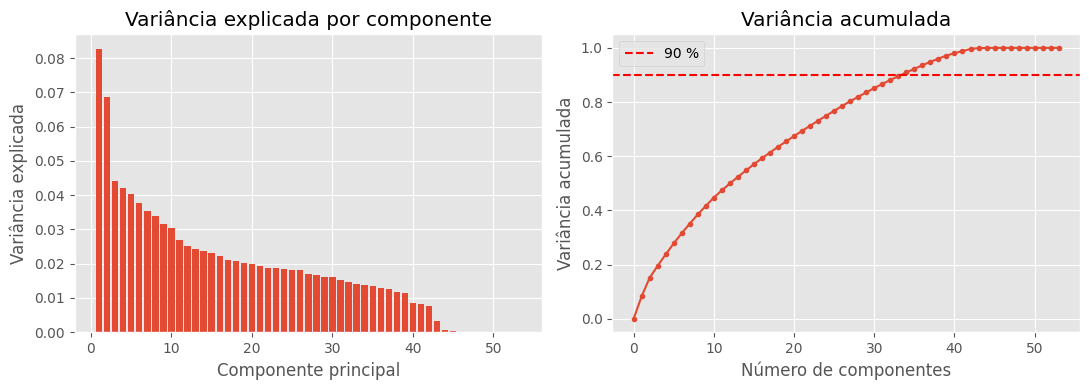

In [447]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.base import clone
# esse clone é usado pra não mexer no meu preprocessador original
from sklearn.decomposition import PCA

# dados do treino já pré-processados e normalizados (só para esta análise descritiva)
X_escalado = Pipeline([
    ("prep", clone(preprocessador)),
    ("escala", StandardScaler()),
]).fit_transform(X_train)

N_ATRIBUTOS = X_escalado.shape[1]
LIMIAR_DE_VARIANCIA = 0.9

pca = PCA().fit(X_escalado)
variancia_explicada = pca.explained_variance_ratio_
variancia_acumulada = np.cumsum(variancia_explicada)
n_componentes_90 = int(np.argmax(variancia_acumulada >= LIMIAR_DE_VARIANCIA) + 1)

print(f"Atributos após o pré-processamento: {N_ATRIBUTOS}")
print(f"Componentes necessárias para {LIMIAR_DE_VARIANCIA:.0%} da variância: {n_componentes_90}")

figura, eixos = plt.subplots(1, 2, figsize=(11, 4))

eixos[0].bar(range(1, N_ATRIBUTOS + 1), variancia_explicada)
eixos[0].set(xlabel="Componente principal", ylabel="Variância explicada",
             title="Variância explicada por componente")

eixos[1].plot(range(0, N_ATRIBUTOS + 1), np.r_[0, variancia_acumulada], marker="o", markersize=3)
eixos[1].axhline(LIMIAR_DE_VARIANCIA, linestyle="--", color="red", label="90 %")
eixos[1].set(xlabel="Número de componentes", ylabel="Variância acumulada",
             title="Variância acumulada")
eixos[1].legend()

plt.tight_layout()
plt.show()

Após o pré-processamento, o conjunto tem 53 atributos, e ao aplicar uma redução nos dados de treino normalizados, observamos que são necessárias 34 componentes para explicar 90 % da variância, e que a variância acumulada cresce de forma gradual, sem que as primeiras componentes concentrem a maior parte da informação. No primeiro gráfico, cada barra é um componente, e a altura é a fração da variância que ela explica. No segundo gráfico, vemos a soma das barras do primeiro gráfico, e a linha vermelha tracejada marca 90 %. A curva cruza essa linha em 34 componentes, e é isso que a primeira linha da saída diz. Visto isso, concluimos que a informação esta bem espalhada e as últimas componentes não carregam nada, ja que explicam aproximadamente 0% da variância. 

Por isso, o número de componentes será tratado como hiperparâmetro e testado pelo Optuna. Assim, vamos seguir para o Optuna, criando a instancia e definindo o intervalo dos hiperparâmetros.

In [448]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

def cria_instancia_modelo_knn(trial):
    escala = trial.suggest_categorical("escala", ["standard", "power"])
    escalador = StandardScaler() if escala == "standard" else PowerTransformer()

    reducao = trial.suggest_categorical("reducao", ["nenhuma", "pca", "rfe"])
    if reducao == "pca":
        n_componentes = trial.suggest_int("n_componentes", 5, N_ATRIBUTOS - 5)
        passo_reducao = PCA(n_components=n_componentes, random_state=SEMENTE_ALEATORIA)
    elif reducao == "rfe":
        n_atributos = trial.suggest_int("n_atributos", 5, N_ATRIBUTOS - 5)
        passo_reducao = RFE(
            LogisticRegression(max_iter=1000),
            n_features_to_select=n_atributos,
            step=0.1,
        )
    else:
        passo_reducao = "passthrough"

    hparam_knn = {
        "n_neighbors": trial.suggest_int("n_neighbors", 3, 300, log=True),
        "weights": trial.suggest_categorical("weights", ["uniform", "distance"]),
        "p": trial.suggest_int("p", 1, 2),
    }

    return Pipeline([
        ("prep", preprocessador),
        ("escala", escalador),
        ("reducao", passo_reducao),
        ("modelo", KNeighborsClassifier(**hparam_knn)),
    ])

Justificativa dos intervalos dos hiperparâmetros:
- escala: mesma ideia da regressão logística 
- n_componentes e n_atributos: o limite inferior evita reduções extremas, o superior (53 − 5) evita pedir mais colunas do que existem em um fold da validação cruzada, e o RFE usa uma regressão logística só para ranquear os atributos com step=0.1 para ser mais rápido.
- reducao: escolhe entre não reduzir, usar o PCA (que cria componentes combinando os atributos) ou o RFE (que mantém só os atributos mais importantes segundo uma regressão logística)
- n_neighbors: varia de 3 a 300 em escala logarítmica, pois valores muito pequenos geram probabilidades grosseiras (com k = 1 só existem 0 e 1) e aumentam a sensibilidade a ruído, enquanto o limite de 300 (cerca de 5 % dos 5800 pacientes de treino de cada fold) permite probabilidades bem suavizadas. A escala logarítmica é usada porque a diferença entre 3 e 10 vizinhos importa muito mais que entre 250 e 300.
- weights: compara dar o mesmo peso a todos os vizinhos (uniform) ou mais peso aos mais próximos (distance)
- p: escolhe entre a distância de Manhattan (p = 1) e a euclidiana (p = 2)

Tendo em vista isso, vamos continuar para a função objetivo e de estudo já feitas anteriormente no outro modelo.

In [449]:
def funcao_objetivo_knn(trial, X, y, cv):
    modelo = cria_instancia_modelo_knn(trial)
    notas = cross_val_score(modelo, X, y, scoring="average_precision", cv=cv, n_jobs=-1)
    return notas.mean()
    
NOME_ESTUDO_KNN = "knn_pr-auc"

estudo_knn = create_study(
    direction="maximize",
    sampler=TPESampler(seed=SEMENTE_ALEATORIA),
    study_name=NOME_ESTUDO_KNN,
    storage=f"sqlite:///{NOME_ESTUDO_KNN}.db",
    load_if_exists=True,
)

def funcao_objetivo_parcial_knn(trial):
    return funcao_objetivo_knn(trial, X_train, y_train, cv)

Por fim, vamos fazer a busca dos melhores hiperparâmetros no KNN.

In [450]:
NUM_TENTATIVAS = 100

feitos = len([t for t in estudo_knn.trials if t.state.name == "COMPLETE"])
estudo_knn.optimize(funcao_objetivo_parcial_knn, n_trials=max(0, NUM_TENTATIVAS - feitos))

melhor_trial_knn = estudo_knn.best_trial

print(f"Número do melhor trial: {melhor_trial_knn.number}")
print(f"Parâmetros do melhor trial: {melhor_trial_knn.params}")
print(f"O melhor valor para pr_auc foi: {estudo_knn.best_value}")

Número do melhor trial: 51
Parâmetros do melhor trial: {'escala': 'power', 'reducao': 'rfe', 'n_atributos': 20, 'n_neighbors': 102, 'weights': 'distance', 'p': 1}
O melhor valor para pr_auc foi: 0.5723153933993217


Nesses resultados foi possível ver que o melhor trial foi o 51, e os hiperparâmetros do melhor trial foram: {'escala': 'power', 'reducao': 'rfe', 'n_atributos': 20, 'n_neighbors': 102, 'weights': 'distance', 'p': 1}. Além disso, O KNN otimizado chegou a 0,572 de PR-AUC, contra 0,436 do KNN padrão. Esse ganho de 0,136 é enorme perto da variação entre folds, mostrando uma grande melhora dessa métrica após o Optuna. O Optuna escolheu o RFE acima do PCA provavelmente porque o RFE é supervisionado (usa o target), e o PCA não é. Como nenhum valor ficou colado na borda do intervalo, concluímos que o intervalo cobriu um espaço bom. 

Mas a escolha do RFE acima do PCA ser por esse motivo é uma hipótese, por isso, vamos analisar se a redução realmente ajudou.

In [451]:
df = estudo_knn.trials_dataframe()
df = df[df["state"] == "COMPLETE"]

print(df.groupby("params_reducao")["value"].agg(["count", "mean", "max"]).round(4))

                count    mean     max
params_reducao                       
nenhuma            11  0.5226  0.5653
pca                10  0.5230  0.5529
rfe                79  0.5565  0.5723


Comparando os tipos de redução, o melhor trial com RFE (0.5723) ficou apenas 0.007 acima do melhor trial sem redução (0.5653), diferença provavelmente menor que a variação entre folds, e o PCA ficou abaixo das duas opções (0.5529). A média do RFE é favorecida porque o Optuna sorteou o RFE em 79 dos 100 trials (e nenhuma e pca em apenas 11 e 10), além disso, o PCA é desfavorecido pelo motivo falado anteriormente: ele não é supervisionado, e não usa o target. Portanto, a maior parte da melhora do K-NN veio do ajuste de n_neighbors, como vamos ver em um gráfico mais a frente, e a redução de dimensionalidade contribuiu, no máximo, de forma marginal.

Vamos observar todas as métricas com o KNN otimizado pela busca dos melhores hiperparâmetros.

In [452]:
knn_otimizado = cria_instancia_modelo_knn(melhor_trial_knn)

res_knn_otimizado = cross_validate(knn_otimizado, X_train, y_train, cv=cv, scoring=metricas)

for nome in metricas:
    print(f"{nome}: {res_knn_otimizado['test_' + nome].mean():.3f}")

accuracy: 0.779
precisao: 0.650
recall: 0.324
f1: 0.431
pr_auc: 0.572
roc_auc: 0.793


A otimização melhorou muito o KNN, dado que o pr_auc subiu de 0.436 para 0.572 e o roc_auc de 0.714 para 0.793. A precisão também subiu (0.526 para 0.650) e a acurácia chegou a 0.779, acima do baseline (0.741). Entretanto o recall não obteve uma melhora considerável. Isso, no geral, é consistente com as hipóteses levantadas, pois com k = 102 as probabilidades deixam de ser grosseiras e a ordenação do risco melhora. O desempenho final é equivalente ao da regressão logística otimizada.

Vamos plotar um gráfico do histórico de busca do Optuna e um gráfico de barras da importância dos hiperparâmetros escolhidos para o modelo.

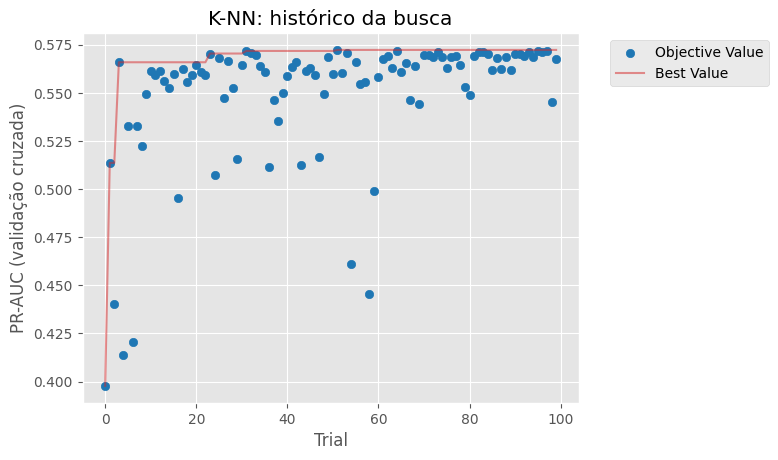

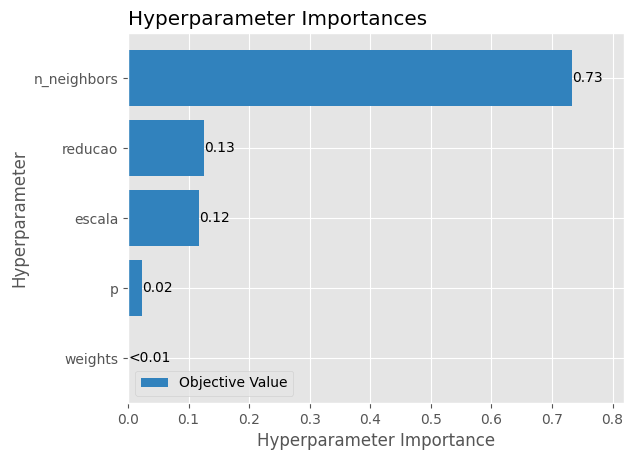

In [453]:
import warnings
import matplotlib.pyplot as plt
from optuna.exceptions import ExperimentalWarning
from optuna.visualization.matplotlib import plot_param_importances, plot_optimization_history

warnings.filterwarnings("ignore", category=ExperimentalWarning)

ax = plot_optimization_history(estudo_knn)
ax.set_ylabel("PR-AUC (validação cruzada)")
ax.set_title("K-NN: histórico da busca")
plt.show()

plot_param_importances(estudo_knn)
plt.show()

O gráfico de histórico mostra que a maior parte do ganho aconteceu nos primeiros trials, e assim, a busca estabilizou por volta do trial 30. Isso indica que 100 trials foram suficientes para a busca convergir. Para o segundo gráfico, ficou claro que o hiperparâmetro mais importante é o n_neighbors, uma vez que ele sozinho explica a maior parte da variação do PR-AUC entre os trials, ainda concordando com a hipótese do início, em que o número de vizinhos controla o quanto as probabilidades são suavizadas, e com k pequeno o modelo é ruim.


### Floresta aleatória

Iremos seguir para o nosso terceiro modelo, que será a floresta aleatória, um algoritmo que combina o resultado de diversas árvores de decisão por meio do bagging (cada árvore é treinada com uma amostra aleatória dos pacientes (com reposição) e, em cada divisão, considera apenas um subconjunto aleatório dos atributos; a previsão final é a média das probabilidades de todas as árvores.) para alcançar um único resultado. 

As árvores tomam decisões por limiares nos valores dos atributos, então não dependem da escala deles, e por isso não foi incluido a normalização neste pipeline. Vamos começar com um modelo padrão do scikit-learn (100 árvores, sem limite de profundidade) como referência.

In [454]:
from sklearn.ensemble import RandomForestClassifier

flo_al = Pipeline([
    ("prep", preprocessador),
    ("modelo", RandomForestClassifier(random_state=SEMENTE_ALEATORIA, n_jobs=-1)),
])

res_flo_al = cross_validate(flo_al, X_train, y_train, cv=cv, scoring=metricas)

for nome in metricas:
    print(f"{nome}: {res_flo_al['test_' + nome].mean():.3f}")

accuracy: 0.785
precisao: 0.660
recall: 0.350
f1: 0.457
pr_auc: 0.583
roc_auc: 0.801


Sem nenhum ajuste, esse resultado ja foi muito bom. Até agora, esse modelo tem o melhor PR-AUC e o melhor ROC-AUC dos algoritmos, sem qualquer otimização. Uma possível explicação é que as árvores capturam relações não lineares e interações entre as variáveis clínicas, o que a regressão logística (linear) não faz, e que o K-NN tem dificuldade de aproveitar em um espaço com dezenas de atributos. O recall (0.350) continua baixo, como nos outros modelos, porque o limiar de decisão de 0.5 não foi alterado.

Com valores padrão, cada árvore cresce até o fim sem limite de profundidade, e tende a decorar o treino, por isso, vamos usar o Optuna para testar melhores versões desse modelo. 

Primeiro, vamos criar o espaço de busca com os hiperparâmetros

In [455]:
def cria_instancia_modelo_rf(trial):
    parametros = {
        # espaço de busca
        "n_estimators": trial.suggest_int("n_estimators", 100, 500),
        "max_depth": trial.suggest_int("max_depth", 3, 30),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 50, log=True),
        "max_features": trial.suggest_float("max_features", 0.01, 1.0),
        "class_weight": trial.suggest_categorical("class_weight", [None, "balanced_subsample"]),
        # argumentos fixos
        "random_state": SEMENTE_ALEATORIA,
        "n_jobs": -1,
    }

    return Pipeline([
        ("prep", preprocessador),
        ("modelo", RandomForestClassifier(**parametros)),
    ])

Justificativa dos hiperparâmetros:
- n_estimators(número de árvores): varia de 100 a 500, em que 100 é o padrão do scikit-learn, e mais árvores deixam a média mais estável, mas com ganhos cada vez menores e custo maior de treino. Por isso, o intervalo vai do padrão ate um número alto com maior custo.
- max_depth(profundidade máxima de cada árvore): varia de 3 a 30, para pegar valores pequenos com árvores simples, e valores grandes que fazer com que as árvores decorem o treino. O padrão do scikit-learn é sem limite, e com cerca de 5800 pacientes por fold, o limite de 30 consegue cobrir árvores bem profundas, então o limite superior pega o necessário.  
- min_samples_leaf (mínimo de pacientes em cada folha): varia de 1 a 50 em escala logarítmica, em que 1 é o padrão e permite folhas com um único paciente, e 50 é um valor alto que força folhas mais gerais, suavizando as probabilidades.
- max_features (fração dos atributos considerada em cada divisão): varia de 0.01 a 1.0, já que com 53 atributos, o padrão do scikit-learn (raiz quadrada, cerca de 7 atributos) equivale a aproximadamente 0.13, então o limite inferior cobre, e 1.0 equivale a considerar todos os atributos e se aproxima do bagging comum.
- class_weight: compara não usar peso e o balanced_subsample (este da mais peso aos pacientes que morreram em cada árvore)

Com isso, vamos para a função objetivo e para o estudo dos melhores hiperparâmetros no intervalo estabelecido.

In [456]:
def funcao_objetivo_rf(trial, X, y, cv):
    modelo = cria_instancia_modelo_rf(trial)
    notas = cross_val_score(modelo, X, y, scoring="average_precision", cv=cv)
    return notas.mean()

NOME_ESTUDO_RF = "rf_prauc"

estudo_rf = create_study(
    direction="maximize",
    sampler=TPESampler(seed=SEMENTE_ALEATORIA),
    study_name=NOME_ESTUDO_RF,
    storage=f"sqlite:///{NOME_ESTUDO_RF}.db",
    load_if_exists=True,
)

def funcao_objetivo_parcial_rf(trial):
    return funcao_objetivo_rf(trial, X_train, y_train, cv)

In [457]:
NUM_TENTATIVAS = 100

feitos = len([t for t in estudo_rf.trials if t.state.name == "COMPLETE"])
estudo_rf.optimize(funcao_objetivo_parcial_rf, n_trials=max(0, NUM_TENTATIVAS - feitos))

melhor_trial_rf = estudo_rf.best_trial

print(f"Número do melhor trial: {melhor_trial_rf.number}")
print(f"Parâmetros do melhor trial: {melhor_trial_rf.params}")
print(f"O melhor valor para pr_auc foi: {estudo_rf.best_value}")

Número do melhor trial: 86
Parâmetros do melhor trial: {'n_estimators': 310, 'max_depth': 19, 'min_samples_leaf': 4, 'max_features': 0.0946709108031718, 'class_weight': None}
O melhor valor para pr_auc foi: 0.6031450799302801


Assim, temos uma melhora significativa em relação aos outros modelos. O melhor trial foi o de número 86, com pr_auc de 0.6031 na validação cruzada, acima dos 0.583 da floresta com valores padrão. Como nenhum dos hiperparâmetros ficou colado em uma borda do intervalo de busca, podemos concluir que o espaço definido cobriu o ótimo.

Na mesma ideia dos outros modelos, vamos fazer um modelos com os melhores hiperparâmetros da busca.

In [458]:
rf_otimizado = cria_instancia_modelo_rf(melhor_trial_rf)

res_rf_otimizado = cross_validate(rf_otimizado, X_train, y_train, cv=cv, scoring=metricas)

for nome in metricas:
    print(f"{nome}: {res_rf_otimizado['test_' + nome].mean():.3f}")

accuracy: 0.785
precisao: 0.690
recall: 0.311
f1: 0.428
pr_auc: 0.603
roc_auc: 0.807


Neste modelo, tivemos uma melhora do pr_auc, roc_auc e da precisão, métricas que avaliam a ordenação do risco. Entretanto, o recall e o f1 tiveram uma piora e a acurácia se manteve igual. Isso é esperado, porque a busca otimizou o pr_auc, que não depende de um limiar de decisão, enquanto precisão, recall e f1 são calculados com o limiar padrão de 0.5. Uma possível explicação é que a floresta com folhas com pelo menos 4 pacientes e poucos atributos por divisão, produz probabilidades menos extremas, então menos pacientes ultrapassam 0.5. Ou seja, o modelo acerta mais quando prevê óbito (maior precisão), mas identifica menos óbitos (menor recall).

Por fim, vamos fazer os gráficos do histórico de busca do Optuna e dos hiperparâmetros mais importantes

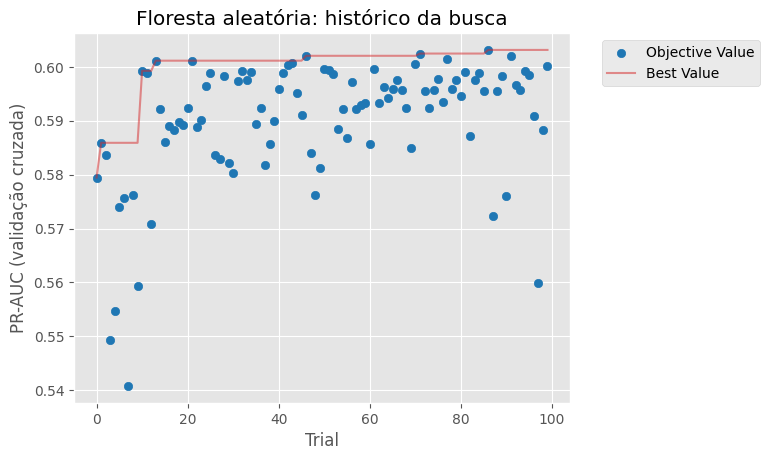

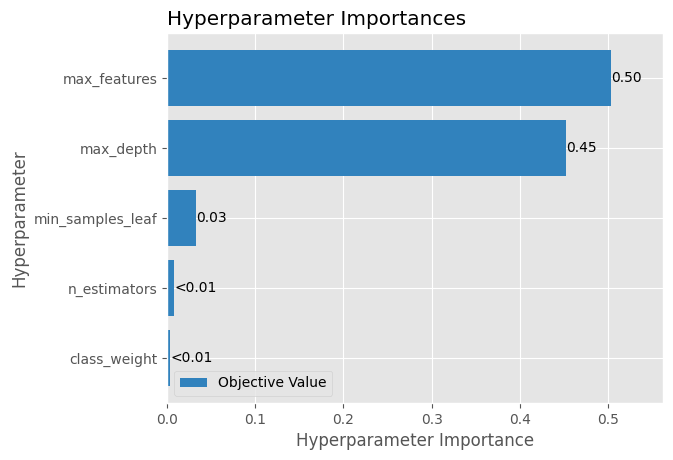

In [459]:
ax = plot_optimization_history(estudo_rf)
ax.set_ylabel("PR-AUC (validação cruzada)")
ax.set_title("Floresta aleatória: histórico da busca")
plt.show()

plot_param_importances(estudo_rf)
plt.show()

No histórico de busca, vemos que a maior parte do ganho veio cedo, e depois disso, a melhora foi baixa. Por isso, os 100 trials foram suficientes para a busca, que estabilizou em pouco mais de 10 trials. Além disso, no gráfico de importância, o max_features foi o mais importante, e uma possível explicação para isso seria que considerar poucos atributos em cada divisão deixa as árvores mais diferentes entre si, o que torna a média da floresta mais estável. O segundo hiperparâmetro mais importante foi o max_depth, que vem principalmente de profundidades muito baixas terem tido notas ruins.

### Gradient Boosting

Vamos agora para o Gradiente Boosting, que também combina muitas árvores de decisão, mas de um jeito diferente da floresta: em vez de treinar árvores independentes e fazer a média, ele as treina em sequência, e cada nova árvore tenta corrigir os erros cometidos pelas anteriores. Usaremos o HistGradientBoostingClassifier do scikit-learn, que agrupa os valores dos atributos em faixas (histogramas) para treinar mais rápido. 

Assim como na floresta, este modelo não depende da escala dos atributos, e por isso não incluímos normalização no pipeline. Começamos com os valores padrão como referência.

In [460]:
from sklearn.ensemble import HistGradientBoostingClassifier

gb = Pipeline([
    ("prep", preprocessador),
    ("modelo", HistGradientBoostingClassifier(random_state=SEMENTE_ALEATORIA)),
])

res_gb = cross_validate(gb, X_train, y_train, cv=cv, scoring=metricas)

for nome in metricas:
    print(f"{nome}: {res_gb['test_' + nome].mean():.3f}")

accuracy: 0.781
precisao: 0.622
recall: 0.398
f1: 0.485
pr_auc: 0.590
roc_auc: 0.795


Com valores padrão, o Gradient Boosting obteve pr_auc de 0.590 e roc_auc de 0.795, resultado equivalente ao da floresta aleatória padrão (0.583 e 0.801), e claramente acima da regressão logística padrão (0.558 de pr_auc). Diferentemente dos modelos anteriores, ele também teve o maior recall (0.398) e o melhor f1 (0.485), ao custo de uma precisão um pouco menor (0.622). Uma possível hipótese é que, no boosting, cada árvore corrige os erros das anteriores e as probabilidades finais ficam mais espalhadas do que na média de uma floresta, então mais pacientes ultrapassam o limiar de 0.5

Seguimos para o Optuna para melhorar os hiperparâmetros.

In [461]:
from sklearn.ensemble import HistGradientBoostingClassifier

def cria_instancia_modelo_gb(trial):
    parametros = {
        # espaço de busca
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3, log=True),
        "max_iter": trial.suggest_int("max_iter", 50, 600),
        "max_leaf_nodes": trial.suggest_int("max_leaf_nodes", 2, 64, log=True),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 10, 100),
        "l2_regularization": trial.suggest_float("l2_regularization", 1e-6, 10, log=True),
        # argumentos fixos
        "early_stopping": False,
# faz o modelo treinar exatamente max_iter iterações. Sem isso, o scikit-learn pode parar 
# mais cedo por conta própria
        "random_state": SEMENTE_ALEATORIA,
    }

    return Pipeline([
        ("prep", preprocessador),
        ("modelo", HistGradientBoostingClassifier(**parametros)),
    ])

Justificativa dos hiperparâmetros:
- learning_rate (taxa de aprendizado): controla quanto cada nova árvore corrige os erros das anteriores: valores pequenos tornam o aprendizado lento e exigem mais árvores, e valores grandes aprendem rápido, mas com risco de decorar o treino. O valor padrão do scikit-learn é de 0.1, incluido na busca, e o de 0,3 é um valor alto para comparação (caso o melhor hiperparâmetro fique perto da borda, esse intervalo pode ser aumentado)
- max_iter (número de árvores): varia de 50 a 600, em que 100 é o padrão. Ele interage com a taxa de aprendizado, pois taxas menores precisam de mais iterações, e o limite superior de 600 mantém o custo de treino razoável.
- max_leaf_nodes (número máximo de folhas por árvore): varia de 2 a 64, incluindo o padrão (31). No boosting as árvores costumam ser pequenas, e esse intervalo vai de árvores simples a árvores com bastante flexibilidade.
- min_samples_leaf (mínimo de pacientes por folha): varia de 10 a 100, em torno do padrão (20), e valores maiores evitam folhas com poucos pacientes, que decorariam o treino.
- l2_regularization (penalização dos valores das folhas): varia de 1e-6 a 10 em escala logarítmica: o padrão é 0, e 1e-6 se aproxima de não regularizar, enquanto 10 é uma regularização forte

O early_stopping faz o modelo treinar exatamente max_iter iterações. Sem isso, o scikit-learn pode parar  mais cedo por conta própria. Continuemos para o Optuna, com a função objetivo e o estudo.

In [462]:
def funcao_objetivo_gb(trial, X, y, cv):
    modelo = cria_instancia_modelo_gb(trial)
    notas = cross_val_score(modelo, X, y, scoring="average_precision", cv=cv)
    return notas.mean()

NOME_ESTUDO_GB = "gb_pra-uc"

estudo_gb = create_study(
    direction="maximize",
    sampler=TPESampler(seed=SEMENTE_ALEATORIA),
    study_name=NOME_ESTUDO_GB,
    storage=f"sqlite:///{NOME_ESTUDO_GB}.db",
    load_if_exists=True,
)

def funcao_objetivo_parcial_gb(trial):
    return funcao_objetivo_gb(trial, X_train, y_train, cv)

Finalmente, vamos para a busca

In [463]:
NUM_TENTATIVAS = 100

feitos = len([t for t in estudo_gb.trials if t.state.name == "COMPLETE"])
estudo_gb.optimize(funcao_objetivo_parcial_gb, n_trials=max(0, NUM_TENTATIVAS - feitos))

melhor_trial_gb = estudo_gb.best_trial

print(f"Número do melhor trial: {melhor_trial_gb.number}")
print(f"Parâmetros do melhor trial: {melhor_trial_gb.params}")
print(f"O melhor valor para pr_auc foi: {estudo_gb.best_value}")

Número do melhor trial: 42
Parâmetros do melhor trial: {'learning_rate': 0.0476607246640909, 'max_iter': 436, 'max_leaf_nodes': 5, 'min_samples_leaf': 59, 'l2_regularization': 0.010697548670597159}
O melhor valor para pr_auc foi: 0.6063159222629206


Temos uma melhora, mas nada muito diferente do que já tinhamos visto. O boosting (0.606) e a floresta (0.603) ficaram praticamente empatados (a diferença de 0,003 é ruído). Os dois são equivalentes, e ambos superam o K-NN e a regressão logística. Não temos nenhum valor colado na borda, então os intervalos escolhidos foram bons. A combinação escolhida (muitas árvores pequenas, com taxa de aprendizado baixa e folhas com muitos pacientes) é típica de um boosting bem regularizado, em que cada árvore faz uma correção pequena e o modelo é menos propenso a decorar o treino.

Vamos seguir a mesma ideia, fazendo um modelo com os hiperparâmetros otimizados.

In [464]:
gb_otimizado = cria_instancia_modelo_gb(melhor_trial_gb)

res_gb_otimizado = cross_validate(gb_otimizado, X_train, y_train, cv=cv, scoring=metricas)

for nome in metricas:
    print(f"{nome}: {res_gb_otimizado['test_' + nome].mean():.3f}")

accuracy: 0.788
precisao: 0.651
recall: 0.390
f1: 0.487
pr_auc: 0.606
roc_auc: 0.806


A otimização melhorou o Gradient Boosting: o pr_auc subiu de 0.590 para 0.606 e o roc_auc de 0.795 para 0.806, além da precisão (0.622 para 0.651) e da acurácia (0.781 para 0.788). O f1 se manteve (0.485 para 0.487) e o recall caiu apenas de 0.398 para 0.390, diferença desprezível. Ou seja, diferentemente do que ocorreu com a floresta aleatória, o ganho na ordenação do risco não veio acompanhado de uma queda relevante do recall.

Finalmente, vamos observar os gráficos do histórico de busca e dos hiperparâmetros importantes.

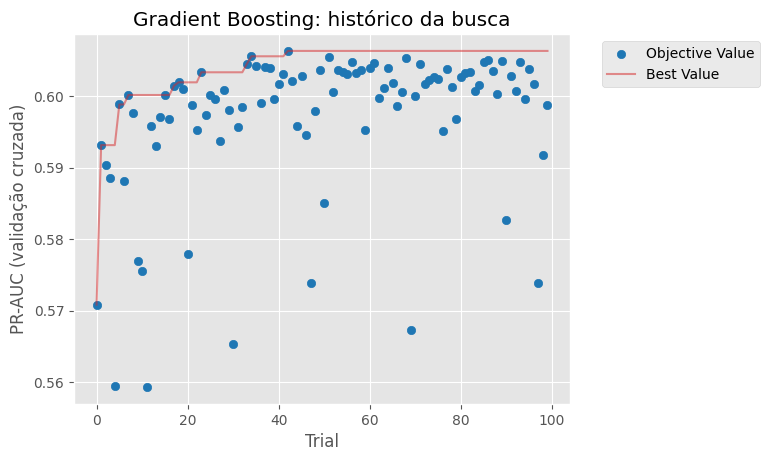

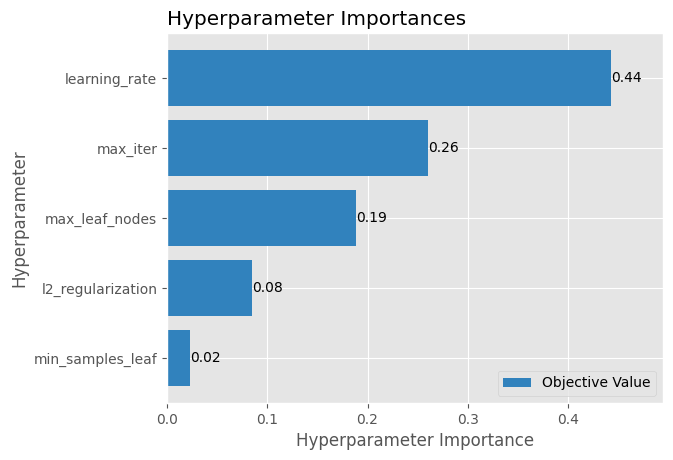

In [465]:
ax = plot_optimization_history(estudo_gb)
ax.set_ylabel("PR-AUC (validação cruzada)")
ax.set_title("Gradient Boosting: histórico da busca")
plt.show()

plot_param_importances(estudo_gb)
plt.show()

No histórico de busca, o ganho se mantem nos primeiro 42 degraus, e depois, sobe pouco. Logo, ficou claro que a busca convergiu.  No gráfico de importância, a learning_rate foi o hiperparâmetro mais importante (0.40), seguida do max_iter (0.29) e do max_leaf_nodes (0.22), o que é coerente com o funcionamento do boosting: a taxa de aprendizado e o número de árvores controlam em conjunto o quanto o modelo se ajusta ao treino.

### SVM

Seguindo para o SVM, vemos que a máquina de vetores de suporte é um algoritmo que classifica dados encontrando uma linha ou hiperplano ótimo que maximiza a distância entre cada classe em um espaço. Como o SVM mede distâncias com uma margem entre pacientes (como o K-NN), ele precisa dos atributos na mesma escala. Por isso o pipeline vai ter o StandardScaler, igual ao do K-NN.

Começaremos com um modelo padrão.

In [466]:
from sklearn.svm import SVC

svm = Pipeline([
    ("prep", preprocessador),
    ("escala", StandardScaler()),
    ("modelo", SVC(kernel="rbf")),
])

res_svm = cross_validate(svm, X_train, y_train, cv=cv, scoring=metricas, n_jobs=-1)

for nome in metricas:
    print(f"{nome}: {res_svm['test_' + nome].mean():.3f}")

accuracy: 0.778
precisao: 0.650
recall: 0.312
f1: 0.421
pr_auc: 0.563
roc_auc: 0.778


Neste resultado, vemos que o modelo aprendeu algo, pois as métricas são melhores que o baseline, mas fica praticamente empatado com os resultados da regressão logística padrão, mostrando-se ser um modelo apenas razoável.

Vamos ver se o Optuna consegue melhorar isso.

In [467]:
from sklearn.preprocessing import PowerTransformer

def cria_instancia_modelo_svm(trial):
    escala = trial.suggest_categorical("escala", ["standard", "power"])
    escalador = StandardScaler() if escala == "standard" else PowerTransformer()

    hparam_svm = {
        # espaço de busca
        "C": trial.suggest_float("C", 1e-3, 1e2, log=True),
        "gamma": trial.suggest_float("gamma", 1e-4, 1e-1, log=True),
        "class_weight": trial.suggest_categorical("class_weight", [None, "balanced"]),
        # argumentos fixos
        "kernel": "rbf",
        "cache_size": 500,
    }

    return Pipeline([
        ("prep", preprocessador),
        ("escala", escalador),
        ("modelo", SVC(**hparam_svm)),
    ])

Justificativa dos hiperparâmetros:
- C: quanto o modelo aceita errar no treino. C pequeno gera uma fronteira mais suave e simples, e C grande tenta acertar todos os pacientes do treino e pode acabar decorando. No limite inferior, a regularização é tão forte que o modelo fica simples demais e quase não se ajusta aos dados. Já no limite superior, o modelo quase não aceita erros no treino e tende a decorar os pacientes (overfitting).
- gamma: define o quão longe a influência de cada paciente alcança. Usa valores altos e baixos em seu intervalo para obter um meio termo entre decorar o treino e uma fronteira suave demais. Sendo isso em torno do valor padrão do scikit-learn
- class_weight: decide entre dar peso para a classe minoritária (morte) ou não

Com isso feito, vamos seguir para a busca.

In [468]:
from sklearn.model_selection import cross_val_score

def funcao_objetivo_svm(trial, X, y, cv):
    modelo = cria_instancia_modelo_svm(trial)
    notas = cross_val_score(modelo, X, y, scoring="average_precision", cv=cv, n_jobs=-1)
    return notas.mean()

NOME_ESTUDO_SVM = "svm_prauc"

estudo_svm = create_study(
    direction="maximize",
    sampler=TPESampler(seed=SEMENTE_ALEATORIA),
    study_name=NOME_ESTUDO_SVM,
    storage=f"sqlite:///{NOME_ESTUDO_SVM}.db",
    load_if_exists=True,
)

def funcao_objetivo_parcial_svm(trial):
    return funcao_objetivo_svm(trial, X_train, y_train, cv)

In [469]:
NUM_TENTATIVAS = 100

feitos = len([t for t in estudo_svm.trials if t.state.name == "COMPLETE"])
estudo_svm.optimize(funcao_objetivo_parcial_svm, n_trials=max(0, NUM_TENTATIVAS - feitos))

melhor_trial_svm = estudo_svm.best_trial

print(f"Número do melhor trial: {melhor_trial_svm.number}")
print(f"Parâmetros do melhor trial: {melhor_trial_svm.params}")
print(f"O melhor valor para pr_auc foi: {estudo_svm.best_value}")

Número do melhor trial: 41
Parâmetros do melhor trial: {'escala': 'power', 'C': 14.16757563408142, 'gamma': 0.001413915025808366, 'class_weight': 'balanced'}
O melhor valor para pr_auc foi: 0.592774372320398


O resultado é bom. O Optuna levou o SVM de 0.563 para 0.593 de pr_auc, um ganho de 0.030. É mais do que a regressão logística teve e menos do que o K-NN. Os valores não ficaram na borda, então o intervalo dos hiperparâmetros foi bom

Vamos prosseguir para o modelo otimizado.

In [470]:
svm_otimizado = cria_instancia_modelo_svm(melhor_trial_svm)

res_svm_otimizado = cross_validate(svm_otimizado, X_train, y_train, cv=cv, scoring=metricas, n_jobs=-1)

for nome in metricas:
    print(f"{nome}: {res_svm_otimizado['test_' + nome].mean():.3f}")

accuracy: 0.699
precisao: 0.454
recall: 0.779
f1: 0.573
pr_auc: 0.593
roc_auc: 0.802


Tivemos uma melhora em algumas métricas, como o recall, o f1, o pr_auc e o roc_auc, porém a acurácia e a precisão apresentaram um piora. Isso mostra que a ordenação do risco melhorou e o ganho do recall veio provavelmente do class_weight = balanced, que deu mais peso para as mortes no treino.

Vamos visualizar isso no histórico de busca do Optuna e na importancia dos hiperparâmetros.

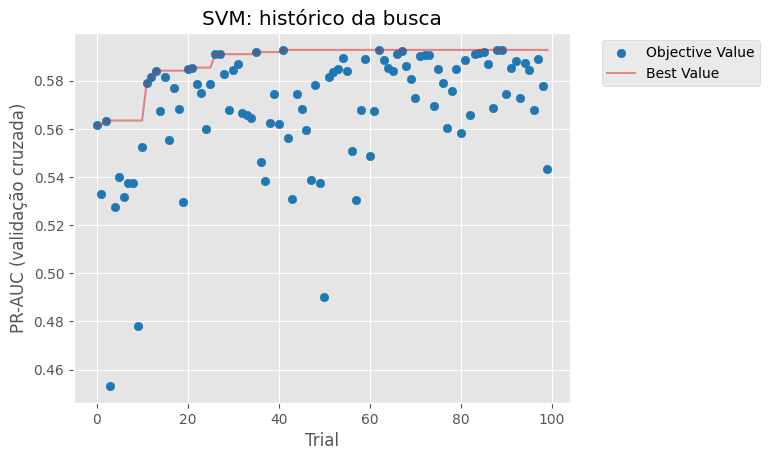

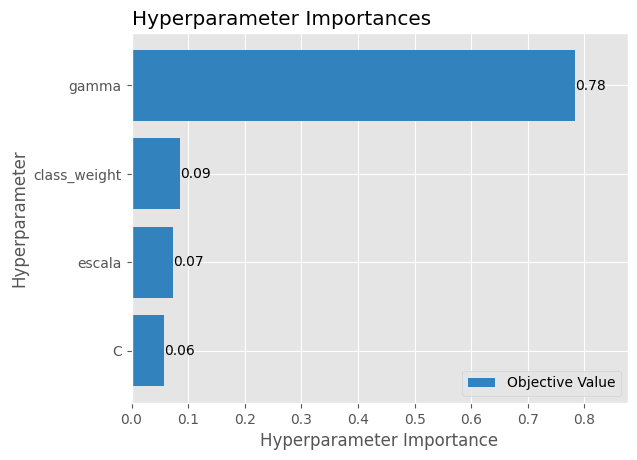

In [471]:
import matplotlib.pyplot as plt
from optuna.visualization.matplotlib import plot_param_importances, plot_optimization_history

ax = plot_optimization_history(estudo_svm)
ax.set_ylabel("PR-AUC (validação cruzada)")
ax.set_title("SVM: histórico da busca")
plt.show()

plot_param_importances(estudo_svm)
plt.show()

Como podemos observar, no histórico de busca, o pr_auc se estabiliza aproximadamente nos 40 trials, mostrando que a busca convergiu e que os 100 trials foram suficientes. Dentro dos intervalos testados, o gamma é o mais importante. Isso acontece pois com gamma muito pequeno, a fronteira fica quase reta e o modelo perde o que o kernel RBF oferece. Com gamma muito grande, ele decora o treino. Os dois extremos dão resultados ruins, então o pr_auc despenca nessas regiões e apenas o meio termo da resultados bons.

## Comparando os modelos 

Vamos fazer uma tabela comparando todos os modelos criados, utilizando o mesmo cv para a comparação ser justa.

In [472]:
import pandas as pd

resultados_cv = {
    "Baseline": res,
    "Reg. logística": res_lr_otimizada,
    "K-NN": res_knn_otimizado,
    "Floresta aleatória": res_rf_otimizado,
    "Gradient Boosting": res_gb_otimizado,
    "SVM": res_svm_otimizado,
}

linhas = {}
for nome_modelo, r in resultados_cv.items():
    linhas[nome_modelo] = {
        m: f"{r['test_' + m].mean():.3f} " for m in metricas
    }

tabela_cv = pd.DataFrame(linhas).T
tabela_cv

,accuracy,precisao,recall,f1,pr_auc,roc_auc
Baseline,0.741,0.000,0.000,0.000,0.259,0.500
Reg. logística,0.779,0.627,0.368,0.463,0.566,0.790
K-NN,0.779,0.650,0.324,0.431,0.572,0.793
Floresta aleatória,0.785,0.690,0.311,0.428,0.603,0.807
Gradient Boosting,0.788,0.651,0.390,0.487,0.606,0.806
SVM,0.699,0.454,0.779,0.573,0.593,0.802


Como podemos observar, todos os modelos aprenderam algo, já que ganham do baseline. Ademais, em relação a nossa métrica principal pr_auc, o melhor modelo é o gradient boosting.

Vamos plotar um gráfico para ver essa comparação

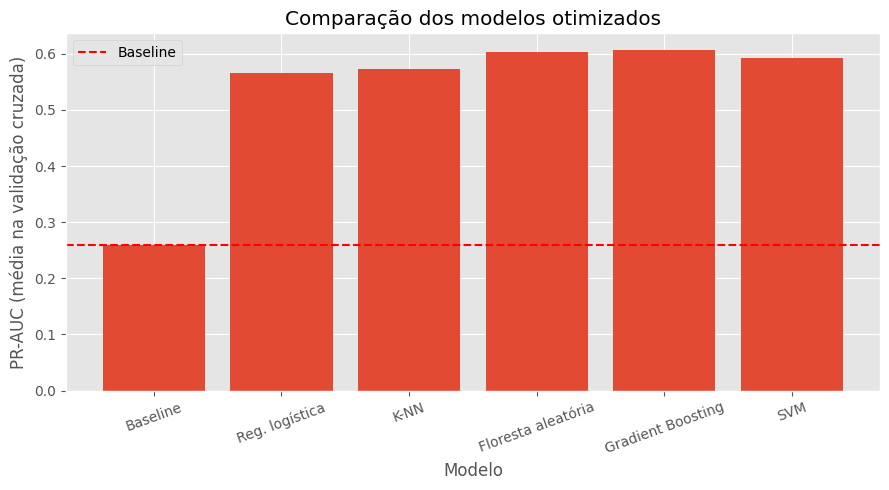

In [473]:
import matplotlib.pyplot as plt

nomes = list(resultados_cv)
pr_aucs = [resultados_cv[n]["test_pr_auc"].mean() for n in nomes]

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(nomes, pr_aucs)
ax.axhline(pr_aucs[0], linestyle="--", color="red", label="Baseline")
ax.set_xlabel("Modelo")
ax.set_ylabel("PR-AUC (média na validação cruzada)")
ax.set_title("Comparação dos modelos otimizados")
ax.legend()
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Mesmo que por pouco, o gradient boosting ganha a competição, então vamos avaliar o conjunto de teste nele.

In [474]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, average_precision_score, roc_auc_score)

# treina o modelo final com todo o treino
gb_final = cria_instancia_modelo_gb(melhor_trial_gb)
gb_final.fit(X_train, y_train)

pred = gb_final.predict(X_test)
prob = gb_final.predict_proba(X_test)[:, 1]

print(f"accuracy: {accuracy_score(y_test, pred):.3f}")
print(f"precisao: {precision_score(y_test, pred, zero_division=0):.3f}")
print(f"recall: {recall_score(y_test, pred, zero_division=0):.3f}")
print(f"f1: {f1_score(y_test, pred, zero_division=0):.3f}")
print(f"pr_auc: {average_precision_score(y_test, prob):.3f}")
print(f"roc_auc: {roc_auc_score(y_test, prob):.3f}")

accuracy: 0.791
precisao: 0.649
recall: 0.419
f1: 0.510
pr_auc: 0.627
roc_auc: 0.813


Os números no teste ficaram parecidos com os da validação cruzada, até um pouco melhores. Isso é um bom sinal. Significa que a validação cruzada foi uma boa estimativa do desempenho em pacientes novos, e que a busca do Optuna não causou overfitting relevante.

Por fim, vamos explicar o modelo final para entender em que ele se baseia com a ferramenta de importância por permutação: 

1. Pega o conjunto de teste e embaralha os valores de um atributo (por exemplo, a idade), quebrando a relação dele com o desfecho.
2. Mede quanto o pr_auc do modelo piora.
3. Se piora muito, o modelo dependia daquele atributo. Se não muda, o atributo era pouco usado.
4. Repete 20 vezes para cada atributo, para não depender de um único embaralhamento.

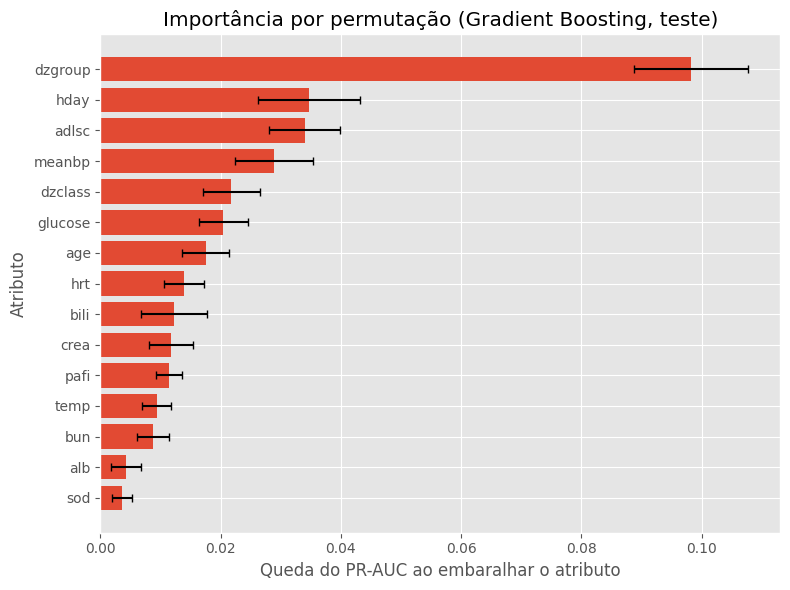

In [475]:
import numpy as np
from sklearn.inspection import permutation_importance

imp = permutation_importance(
    gb_final, X_test, y_test,
    scoring="average_precision", n_repeats=20,
    random_state=SEMENTE_ALEATORIA, n_jobs=-1,
)

ordem = np.argsort(imp.importances_mean)[::-1][:15]
nomes_cols = np.array(X_test.columns)

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(nomes_cols[ordem][::-1], imp.importances_mean[ordem][::-1],
        xerr=imp.importances_std[ordem][::-1], capsize=3)
ax.set_xlabel("Queda do PR-AUC ao embaralhar o atributo")
ax.set_ylabel("Atributo")
ax.set_title("Importância por permutação (Gradient Boosting, teste)")
plt.tight_layout()
plt.show()

Para entender em que o modelo final se baseia, foi usada a importância por permutação. Essa técnica embaralha, no conjunto de teste, os valores de um atributo por vez, o que quebra a relação dele com o desfecho, e mede o quanto o pr_auc do modelo piora. Se a queda é grande, o modelo dependia daquele atributo, e se é pequena, o atributo era pouco usado. O processo foi repetido 20 vezes para cada atributo, e as barras de erro do gráfico representam o desvio-padrão entre essas repetições. Como o embaralhamento é feito no pipeline completo, ele atua nas colunas originais (como a idade ou o diagnóstico) e não nas colunas criadas pelo one-hot, o que facilita a interpretação.

Como podemos observar no gráfico, o atributo mais importante foi o dzgroup, o diagnóstico do paciente: embaralhá-lo derruba o pr_auc em cerca de 0,10, quase o triplo do segundo colocado. Isso é coerente com a análise exploratória, em que a taxa de morte variava de 5,5% (câncer de cólon) a 60% (coma) entre os grupos. Em seguida aparecem hday, adlsc e meanbp, com quedas entre 0,03 e 0,035. Como as barras de erro desses três se sobrepõem, não é possível afirmar qual deles é mais importante, apenas que os três pesam bem menos que o diagnóstico. Os demais atributos têm importância menor, chegando a valores próximos de zero, como alb e sod.

## Conclusões e principais aprendizados

Neste trabalho, comparamos cinco algoritmos (regressão logística, K-NN, floresta aleatória, Gradient Boosting e SVM) para prever a morte durante a internação no conjunto SUPPORT2, usando apenas informações disponíveis até o terceiro dia. Todos os modelos ganharam do baseline, cujo pr_auc de 0,259 é só a proporção de mortes no treino, e ficaram entre 0,566 e 0,606 na validação cruzada. Isso mostra que os atributos clínicos carregam informação útil sobre o risco de morte.

O modelo escolhido foi o Gradient Boosting, por ter o maior pr_auc na validação cruzada (0,606), seguido pela floresta aleatória (0,603). Como a diferença entre eles é muito pequena, não é possível afirmar que um seja realmente melhor que o outro, e os dois modelos baseados em árvores ficaram um pouco acima do SVM (0,593), do K-NN (0,572) e da regressão logística (0,566). Uma possível explicação é que as árvores capturam relações não lineares e interações entre as variáveis clínicas. A escolha foi feita antes de olhar o conjunto de teste, que foi usado uma única vez: lá o modelo obteve pr_auc de 0,627 e roc_auc de 0,813, valores consistentes com os da validação cruzada (0,606 e 0,806). Isso indica que a validação cruzada foi uma boa estimativa do desempenho em pacientes novos e que a busca do Optuna não causou overfitting relevante.

Meu principal aprendizado foi o uso do Optuna, que eu tive bastante dificuldade para aprender na prática, mas consegui consolidar neste trabalho. Além disso, o uso do PCA e da importancia por permutação foram desafiadores também para o meu entendimento.

## Uso de IA

O Claude foi utilizado durante esse trabalho para escolher o dataset, me organizar ao longo dos passos do trabalho, conseguir entender os códigos e o que eu deveria fazer em cada parte, e ainda, me ajudar em eventuais dificuldades em que eu estava presa em certa parte.

## Referências

CASSAR, Daniel Roberto. Otimização de hiperparâmetros com Optuna. ATP-203, Aula 7.1. Ilum Escola de Ciência, Campinas.

CASSAR, Daniel Roberto. Redução de dimensionalidade com PCA. ATP-203, Aula 8.0. Ilum Escola de Ciência, Campinas.

CASSAR, Daniel Roberto. Seleção de atributos. ATP-203, Aula 8.1. Ilum Escola de Ciência, Campinas.

DATA HACKERS. Principais métricas de classificação de modelos em machine learning. Medium. Disponível em: <https://medium.com/data-hackers/principais-m%C3%A9tricas-de-classifica%C3%A7%C3%A3o-de-modelos-em-machine-learning-94eeb4b40ea9>. Acesso em: 23 nov. 2026.

DATACAMP. Parameter optimization for machine learning models. Disponível em: <https://www.datacamp.com/pt/tutorial/parameter-optimization-machine-learning-models>. Acesso em: 23 nov. 2026.

IBM. K-nearest neighbors (KNN). Disponível em: <https://www.ibm.com/br-pt/think/topics/knn>. Acesso em: 23 nov. 2026.

IBM. Regressão logística. Disponível em: <https://www.ibm.com/br-pt/think/topics/logistic-regression>. Acesso em: 23 nov. 2026.

IBM. Support Vector Machine (SVM). Disponível em: <https://www.ibm.com/br-pt/think/topics/support-vector-machine>. Acesso em: 23 nov. 2026.

OPTUNA CONTRIBUTORS. Optuna documentation. Disponível em: <https://optuna.readthedocs.io/en/stable/index.html>. Acesso em: 23 nov. 2026.

SCIKIT-LEARN DEVELOPERS. Scikit-learn documentation. Disponível em: <https://scikit-learn.org/stable/>. Acesso em: 23 nov. 2026.

UNIVERSITY OF CALIFORNIA, IRVINE. SUPPORT2. Irvine: UCI Machine Learning Repository. Disponível em: <https://archive.ics.uci.edu/dataset/880/support2>. Acesso em: 23 nov. 2026.